In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import json
import matplotlib.gridspec as gridspec
from tqdm import tqdm
tqdm.pandas()
from scipy.optimize import curve_fit
from scipy import stats
import math
import chemparse
import pickle
import os
from NetworkExpansion import *
from utilities import *

# To avoid future warnings in network expansion
pd.set_option('future.no_silent_downcasting', True)  

# Matplotlib defaults
font = {"sans-serif": "DejaVu Sans", "size": 22}
for key, value in font.items():
        plt.rcParams.update({"font." + key: value})

# SI Figure details
fig_count = 1
fig_path = "../Figures/SIFigures/SIFig_"


/Users/johnmalloy/Lab/Chirality/ChiralExpansion/Code/NetworkExpansion.py:165: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  ec_rns = pd.read_csv('https://rest.kegg.jp/link/enzyme/reaction', sep='\t', header=None).applymap(


# JGI 

Includes scatter plots and achiral/crossover plots for each domain, plus metagenomes

## Scatter Plots of chirality of individual samples

In [36]:
def linlaw(x, a, b) :
    return a * x + b

def powerlaw(x, a, b, c):
    return b*x**a + c

def curve_fit_log_linear(xdata, ydata) :
    xdata_log = np.log10(xdata)
    # Fit linear
    popt_log, pcov_log = curve_fit(linlaw, xdata_log, ydata)
    # y variables as results from fitting
    ydatafit = linlaw(xdata_log, *popt_log)
    return (popt_log, pcov_log, ydatafit)

def curve_fit_log_log(xdata, ydata) :
    
    xdata_log = np.log10(xdata)
    ydata_log = np.log10(ydata)
    # Fit linear
    popt_log, pcov_log = curve_fit(linlaw, xdata_log, ydata_log)
    # y variables as results from fitting
    ydatafit = pow(10, linlaw(xdata_log, *popt_log))
    return (popt_log, pcov_log, ydatafit)

def find_fit(X,Y,color,ax):
    slope, intercept, r_value, p_value, std_err = stats.linregress(X,Y)
    print('Slope: {:.6f}'.format(slope),'Intercept: {:.6f}'.format(intercept),'R-squared: {:.6f}'.format(r_value**2),'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=0, stop=max(X), num=100)
    ax.plot(x_dummy,slope*x_dummy + intercept,color=color)
    ax.fill_between(x_dummy,slope*x_dummy+intercept-std_err,slope*x_dummy+intercept+std_err,color=color, alpha=0.2)


def find_powerlaw_fit(x,y,color):
    if x == 0:
        x = 0.000001
    if y == 0:
        y = 0.000001
    X = np.log10(x)
    Y = np.log10(y)

    slope, intercept, r_value, p_value, std_err = stats.linregress(X,Y)
    print('Slope: {:.6f}'.format(slope),'Intercept: {:.6f}'.format(intercept),'R-squared: {:.6f}'.format(r_value**2),'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=-500, stop=8000, num=100)
    plt.plot(x_dummy,(10**intercept)*(x_dummy**slope) ,color=color)


In [37]:
data_dir = "../Data/"
df = dict()
for domain in ["Archaea", "Metagenome", "Bacteria", "Eukarya", "Biosphere", "LUCA"]:
    df[domain] = pd.read_csv(data_dir + "species_chirality_in_%s.csv"%domain)

color_number = {"LUCA":"#10D410", "Archaea":"#D65E00", "Bacteria":"#0B77B5", 
                "Eukarya":"#E69F03", "Metagenome":"#009E73", "Biosphere": "#4B0092"} 

Slope: -0.000106 Intercept: 0.739776 R-squared: 0.346741 Std_err: 0.000004
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000027 Intercept: 0.653523 R-squared: 0.200469 Std_err: 0.000003
Slope: 0.000009 Intercept: 0.572096 R-squared: 0.097244 Std_err: 0.000000


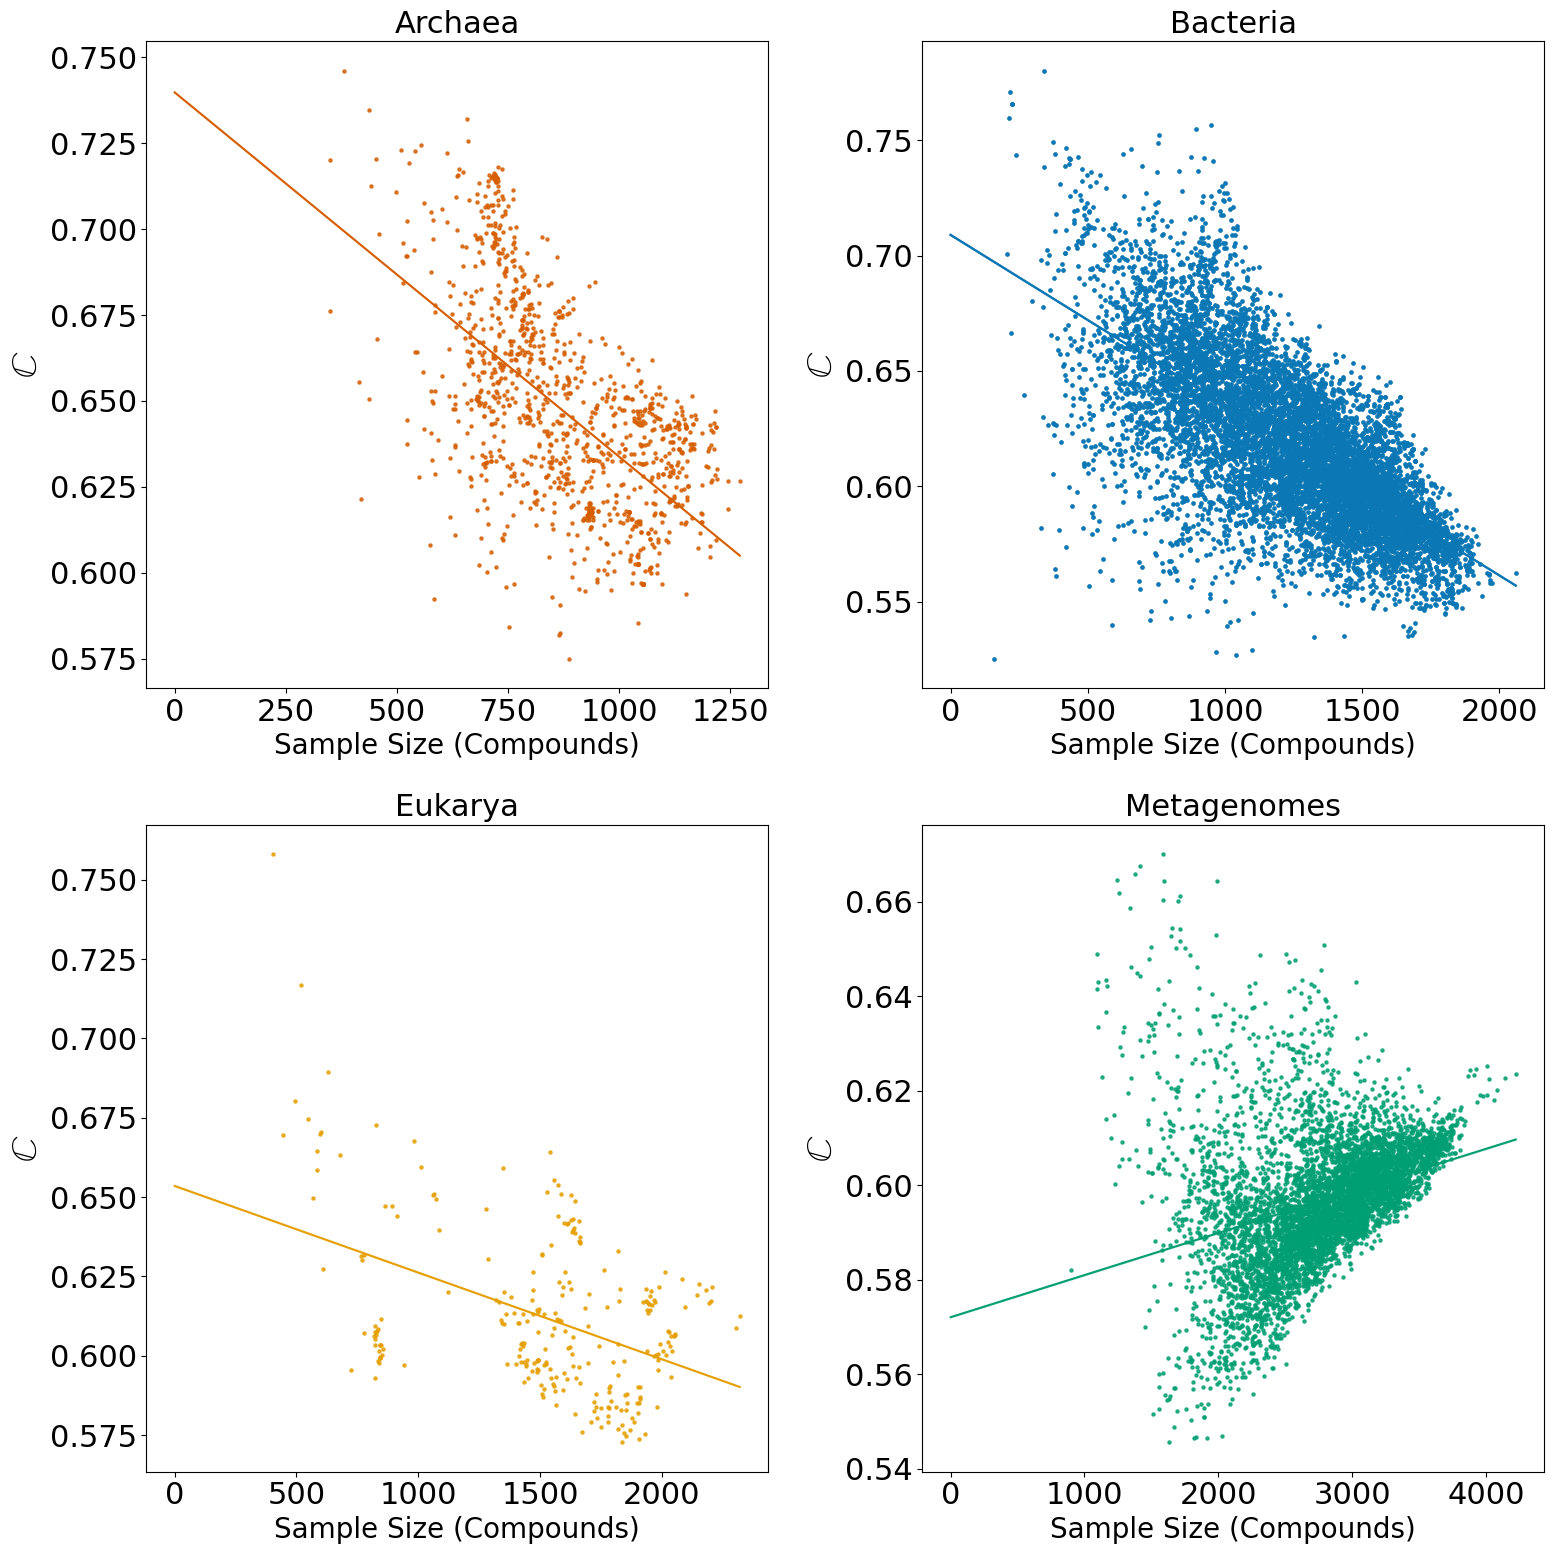

In [39]:
plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(2,2)

# Archaea
ax1 = plt.subplot(gs[0,0])
handles = []
domain = "Archaea"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax1.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax1)
ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
ax1.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax1.set_title(domain, fontsize=22)

ax1 = plt.subplot(gs[0,1])
handles = []
domain = "Bacteria"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax1.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax1)
ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
ax1.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax1.set_title(domain, fontsize=22)

ax2 = plt.subplot(gs[0,1])
handles = []
domain = "Bacteria"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax2.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax2)
ax2.set_ylabel("$\mathbb{C}$", fontsize=26)
ax2.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax2.set_title(domain, fontsize=22)

#Eukarya
ax3 = plt.subplot(gs[1,0])
handles = []
domain = "Eukarya"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax3.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax3)
ax3.set_ylabel("$\mathbb{C}$", fontsize=26)
ax3.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax3.set_title(domain, fontsize=22)

#Metagenomes
ax4 = plt.subplot(gs[1,1])
handles = []
domain = "Metagenome"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax4.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax4)
ax4.set_ylabel("$\mathbb{C}$", fontsize=26)
ax4.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax4.set_title(domain + "s", fontsize=22)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

## Chiral/Achiral crossover (by domain)

In [40]:
### Find which formulas appear in domains

def find_domain(formula, domain_cpds):
    if formula in domain_cpds:
        return 1
    else:
        return 0
    
def getNumHeavyAtoms(f):
    """ Find the number of heavy atoms (non-Hs)

    Args:
        f (dict): dictionary of elements & atom counts

    Returns:
        int: number of non-H atoms
    """
    #Remove Hs
    if "H" in f:
        f.pop("H")

    #Count number of other atoms (heavy atoms are non-Hs)
    return sum(f.values())

def getFormulaDict(f):
    
    return chemparse.parse_formula(f)

In [41]:
# fp = "../Data/chiral_molweight_formula_labels.csv"
# df = pd.read_csv(fp)
# df.head()

keggC_df = pd.read_csv("../../lets-get-kegg/Data/kegg_data_C.csv.zip",
                       index_col=0,
                       compression="zip")

# df["formula_dict"] = df["Formula"].progress_apply(getFormulaDict)
# df["Heavy_Atoms"] = df["formula_dict"].progress_apply(getNumHeavyAtoms)

for domain in ["archaea", "bacteria", "metagenome", "eukarya"]:
    print("---- Analyzing", domain, "----")
    domain_df = pd.read_csv("../Data/" + domain + "_occurance.csv")
    domain_cpds = list(domain_df["Cpd"])

    keggC_df[domain] = keggC_df["compound_id"].apply(find_domain, args=(domain_cpds,))


---- Analyzing archaea ----
---- Analyzing bacteria ----
---- Analyzing metagenome ----
---- Analyzing eukarya ----


In [42]:
### Get all column sorted out - if a compound is present in bacteria, eukarya, archaea, or metagenome, "all" should be 1
all_column = []

for _, row in keggC_df.iterrows():
    found_cpd = 0
    for domain in ["archaea", "bacteria", "metagenome", "eukarya"]:
        if row[domain] == 1 and found_cpd == 0:
            all_column.append(1)
            found_cpd = 1
    if found_cpd == 0:
        all_column.append(0)

keggC_df["all"] = all_column

In [43]:
### Goal - chiral/achiral fraction at each heavy atom value
def get_chiral_fraction(df, domain):
    chiral_fraction = []
    # chiral_fraction = []

    for i in range(1, int(max(df["n_heavy_atoms"]))):
        sub_df = df[df["n_heavy_atoms"] == i]
        #Filter by domain, if domain exists
        if domain:
            sub_df = sub_df[sub_df[domain] == 1]
        else:
            pass

        if len(sub_df) >= 1:
            chiral_fraction.append(float(sub_df["n_chiral_centers"].astype(bool).sum(axis=0) / len(sub_df)))
            # if len(sub_df) < 5 or i == 10:
            #     print(i, sub_df["Chiral_Centers"].astype(bool).sum(axis=0), float(len(sub_df)))
        else:
            chiral_fraction.append(float("NaN"))

    achiral_fraction = []

    for cf in chiral_fraction:
        if not math.isnan(cf):
            achiral_fraction.append(1 - cf)
        else:
            achiral_fraction.append(float("NaN"))

    return chiral_fraction, achiral_fraction

In [44]:
achiral_color = "#FFC012"
chiral_color = "#34CCFF"

In [45]:
# print("---- All KEGG ----")
# chiral_fraction, achiral_fraction = get_chiral_fraction(df, None)

print("---- Metagenomes ---")
mg_chiral_fraction, mg_achiral_fraction = get_chiral_fraction(keggC_df, "metagenome")

print("---- Bacteria ---")
b_chiral_fraction, b_achiral_fraction = get_chiral_fraction(keggC_df, "bacteria")

print("---- Archaea ---")
a_chiral_fraction, a_achiral_fraction = get_chiral_fraction(keggC_df, "archaea")

print("---- Eukarya ---")
e_chiral_fraction, e_achiral_fraction = get_chiral_fraction(keggC_df, "eukarya")

print("---- Metagenomes, Bacteria, Archaea, and Eukarya ----")
all_chiral_fraction, all_achiral_fraction = get_chiral_fraction(keggC_df, "all")


---- Metagenomes ---
---- Bacteria ---
---- Archaea ---
---- Eukarya ---
---- Metagenomes, Bacteria, Archaea, and Eukarya ----


<Figure size 800x800 with 0 Axes>

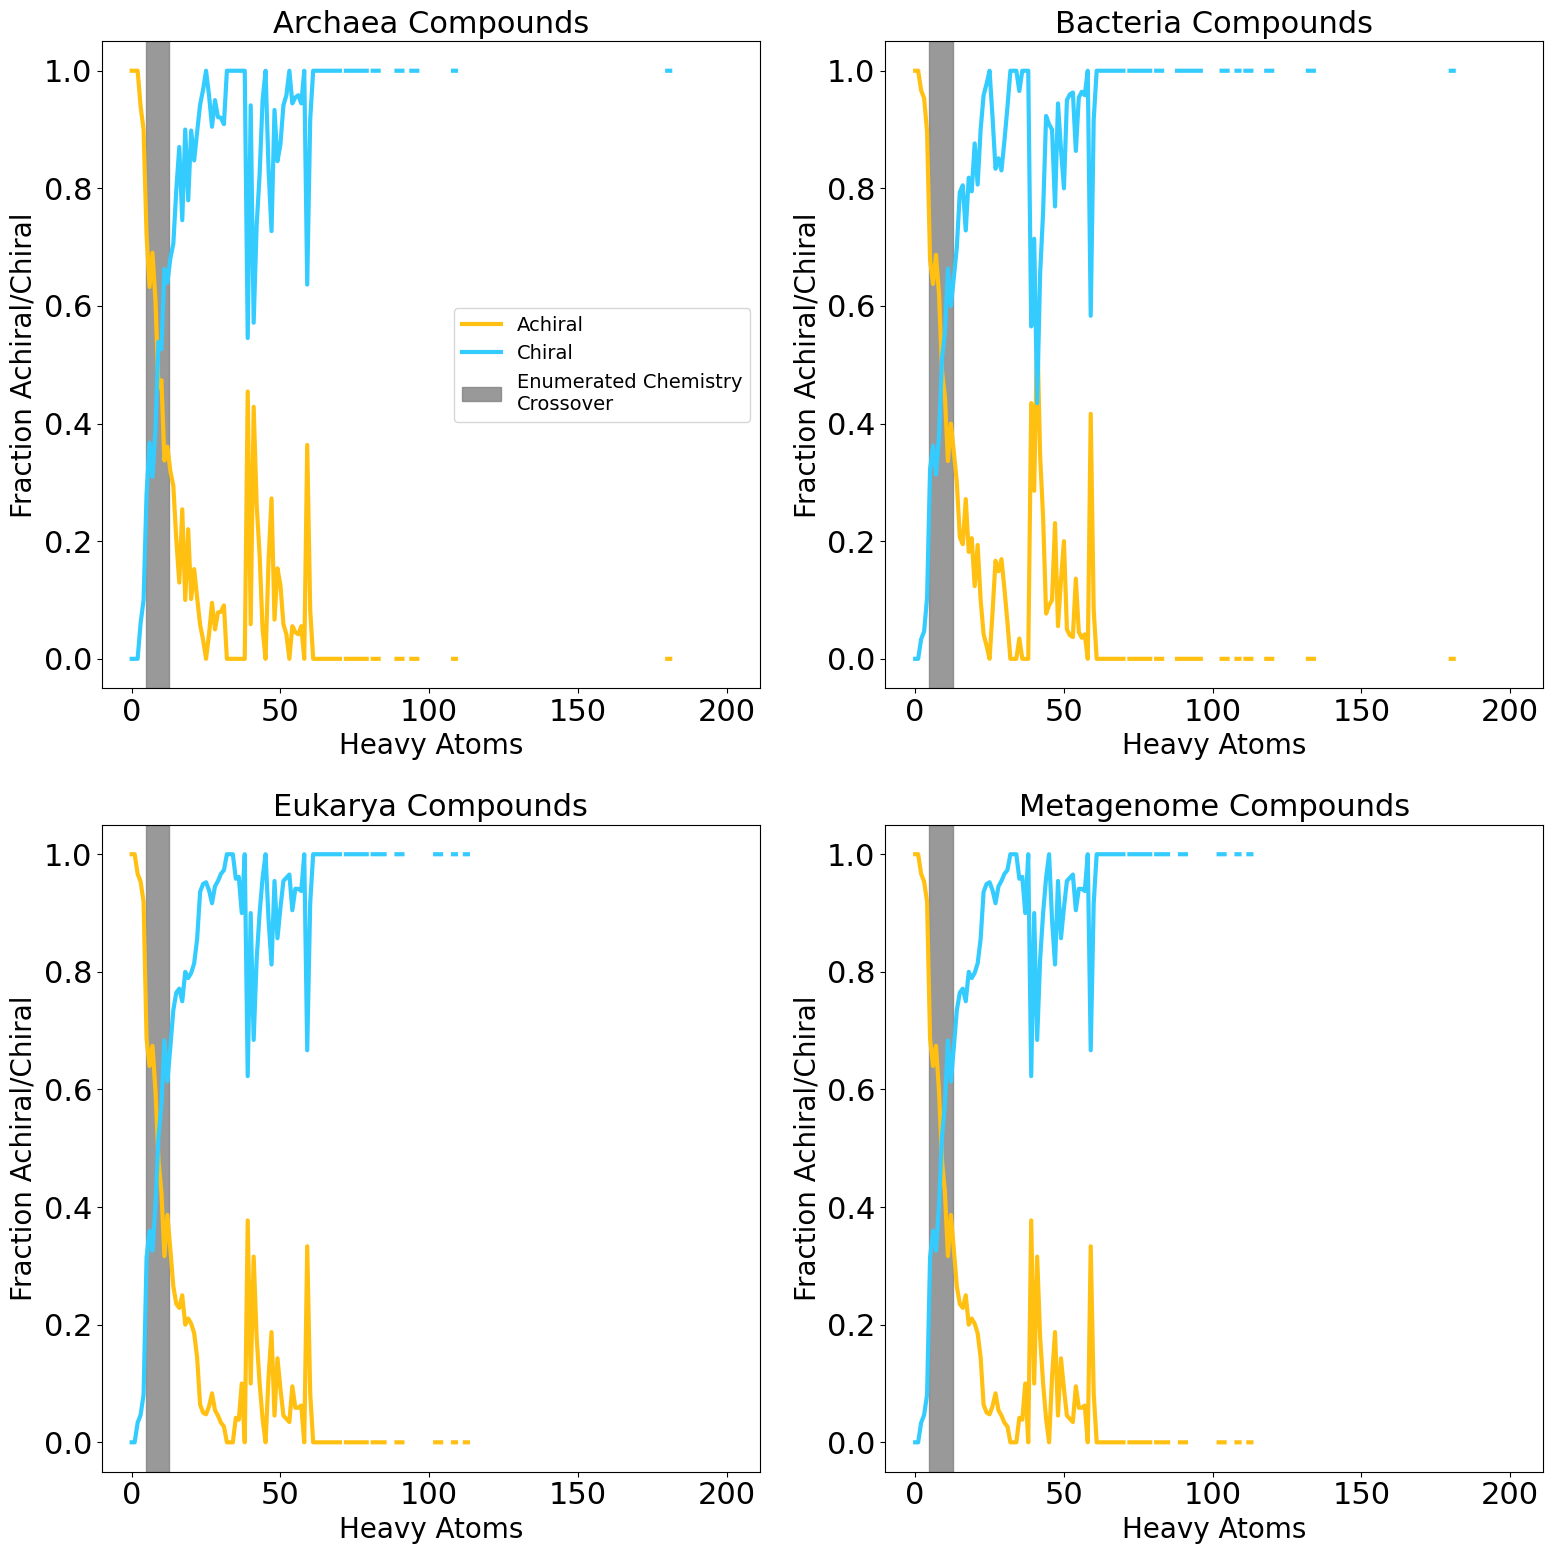

In [46]:
plt.figure(figsize=(8,8))

plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(2,2)

# Archaea
ax1 = plt.subplot(gs[0,0])
ax1.plot(a_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax1.plot(a_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax1.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax1.set_title("Archaea Compounds", fontsize=22)
ax1.legend(prop={"size":14}, facecolor="white")
ax1.set_xlabel("Heavy Atoms", fontsize=20)
ax1.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

#Bacteria
ax2 = plt.subplot(gs[0,1])
ax2.plot(b_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax2.plot(b_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax2.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax2.set_title("Bacteria Compounds", fontsize=22)
ax2.set_xlabel("Heavy Atoms", fontsize=20)
ax2.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

#Eukarya
ax3 = plt.subplot(gs[1,0])
ax3.plot(e_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax3.plot(e_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax3.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax3.set_title("Eukarya Compounds", fontsize=22)
ax3.set_xlabel("Heavy Atoms", fontsize=20)
ax3.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

#Metagenomes
ax4 = plt.subplot(gs[1,1])
ax4.plot(e_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax4.plot(e_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax4.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax4.set_title("Metagenome Compounds", fontsize=22)
ax4.set_xlabel("Heavy Atoms", fontsize=20)
ax4.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

#### Fraction chiral/achiral with standard deviations

No domain data attached

In [27]:
### NOTE: TAKES ~7 MINUTES
import zipfile


#Achiral/chiral stats over all JGI samples
chiral_fracs = []
achiral_fracs = []

with zipfile.ZipFile("../Data/JGI_metagenomes.zip") as z:
      for filename in tqdm(z.namelist()):
            if filename.endswith(".csv"):
                  s1_df = pd.read_csv(z.open(filename))
                  s_df = keggC_df[keggC_df["compound_id"].isin(list(s1_df.compounds))]
                  chiral_fraction, achiral_fraction = get_chiral_fraction(s_df, None)
                  chiral_fracs.append(chiral_fraction)
                  achiral_fracs.append(achiral_fraction)

100%|██████████| 6113/6113 [07:08<00:00, 14.28it/s]


In [28]:
from statistics import mean, stdev

chiral_mean = list(map(np.mean, zip(*chiral_fracs)))
print(chiral_mean)

achiral_mean = list(map(np.mean, zip(*achiral_fracs)))
print(achiral_mean)

chiral_std = list(map(np.std, zip(*chiral_fracs)))
print(chiral_std)

achiral_std = list(map(np.std, zip(*achiral_fracs)))
print(achiral_std)

[np.float64(0.0), np.float64(0.0), np.float64(0.03194814512100824), np.float64(0.052664997462647904), np.float64(0.09241257405853118), np.float64(0.3222978538494611), np.float64(0.3578939880725695), np.float64(0.2987035570512067), np.float64(0.38365662221783103), np.float64(0.5162637129789246), np.float64(0.5451705715190533), np.float64(0.6664850844148845), np.float64(0.6284597286074198), np.float64(0.6930581482411634), np.float64(0.7324717877950443), np.float64(0.8159601135597883), np.float64(0.8263471818147278), np.float64(0.7595254986096096), np.float64(0.8862355556305935), np.float64(0.8096949165607826), np.float64(0.8784470152109451), np.float64(0.8370041633973633), np.float64(0.8941960338013972), np.float64(0.9646049712235679), np.float64(0.9843681828673666), np.float64(0.9969294431678535), np.float64(0.9597415927206165), np.float64(0.9042683501127625), np.float64(0.9028285028499433), np.float64(0.9273558788755976), np.float64(0.9485644579978082), np.float64(0.963567963136809), n

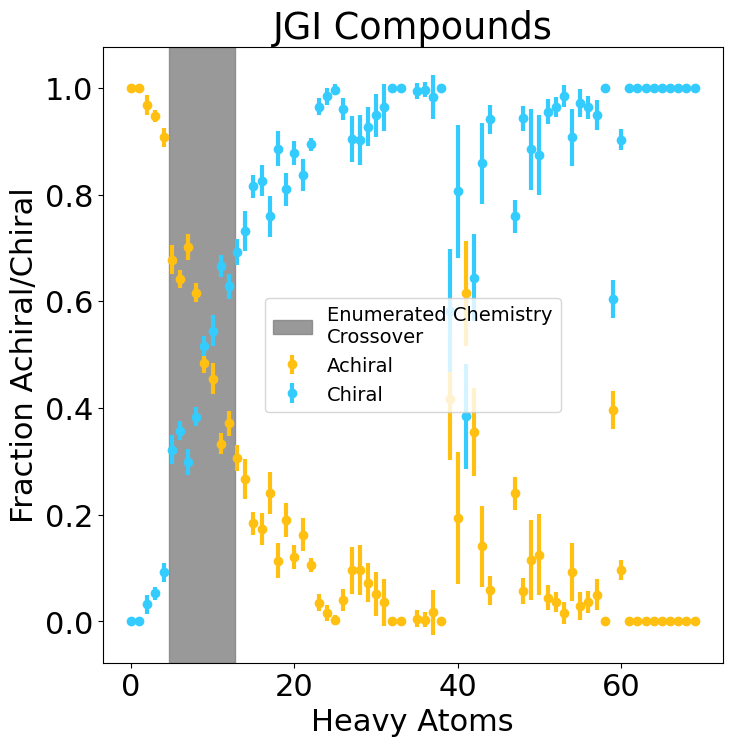

In [29]:
### Test MG fuzzy graph
plt.figure(figsize=(8,8))

plt.errorbar(x=list(range(len(achiral_mean))), y=achiral_mean, yerr=achiral_std, fmt="o", linewidth=3, label="Achiral", color=achiral_color)
plt.errorbar(x=list(range(len(chiral_mean))), y=chiral_mean, yerr=chiral_std, fmt="o", linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")

plt.title("JGI Compounds")
plt.legend(prop={"size":14})

plt.xlabel("Heavy Atoms")
plt.ylabel("Fraction Achiral/Chiral")

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

In [30]:
del(chiral_fracs)
del(achiral_fracs)

#### GDB / JGI / Chiral Order Parameter, no x-limits

In [33]:
gdb_df = pd.read_csv("../Data/GDB_output.csv")

## GDB chiral order parameter (cop = "Chiral Order Parameter")
gdb_counts_df = pd.read_csv("../Data/GDB_raw_counts.csv")
gdb_cop = []

for _, row in gdb_counts_df.iterrows():
    gdb_cop.append(row["count_chiral"] / (row["count_achiral"] + row["count_chiral"]))

print(gdb_cop)

## JGI cop
JGI_cop = []
sub_df = keggC_df[keggC_df["all"] == 1]
for i in range(70):
    sub_df2 = sub_df[sub_df["n_heavy_atoms"] == i]
    achiral = len(sub_df2[sub_df2["n_chiral_centers"] == 0])
    chiral = len(sub_df2[sub_df2["n_chiral_centers"] != 0])
    if achiral + chiral != 0:
        JGI_cop.append(chiral / (achiral + chiral))
    else:
        JGI_cop.append(None)

print(JGI_cop)

[np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.026143790849673203), np.float64(0.04929577464788732), np.float64(0.16754617414248021), np.float64(0.2815533980582524), np.float64(0.390595009596929), np.float64(0.5333333333333333), np.float64(0.6166097838452788), np.float64(0.7176544240400667), np.float64(0.8064989902698734), np.float64(0.8196666666666667), np.float64(0.8593333333333333), np.float64(0.9453333333333334), np.float64(0.9478333333333333), np.float64(0.9648333333333333), np.float64(0.8909636545515172), np.float64(0.978)]
[0.0, 0.0, 0.0, 0.029411764705882353, 0.041666666666666664, 0.1, 0.32786885245901637, 0.36470588235294116, 0.32038834951456313, 0.3989071038251366, 0.5116279069767442, 0.5671641791044776, 0.6867469879518072, 0.6182795698924731, 0.6506849315068494, 0.7285714285714285, 0.7686567164179104, 0.7764705882352941, 0.7291666666666666, 0.7910447761194029, 0.7983870967741935, 0.8114754098360656, 0.8114754098360656, 0.8632478632478633, 0.9387755102040817

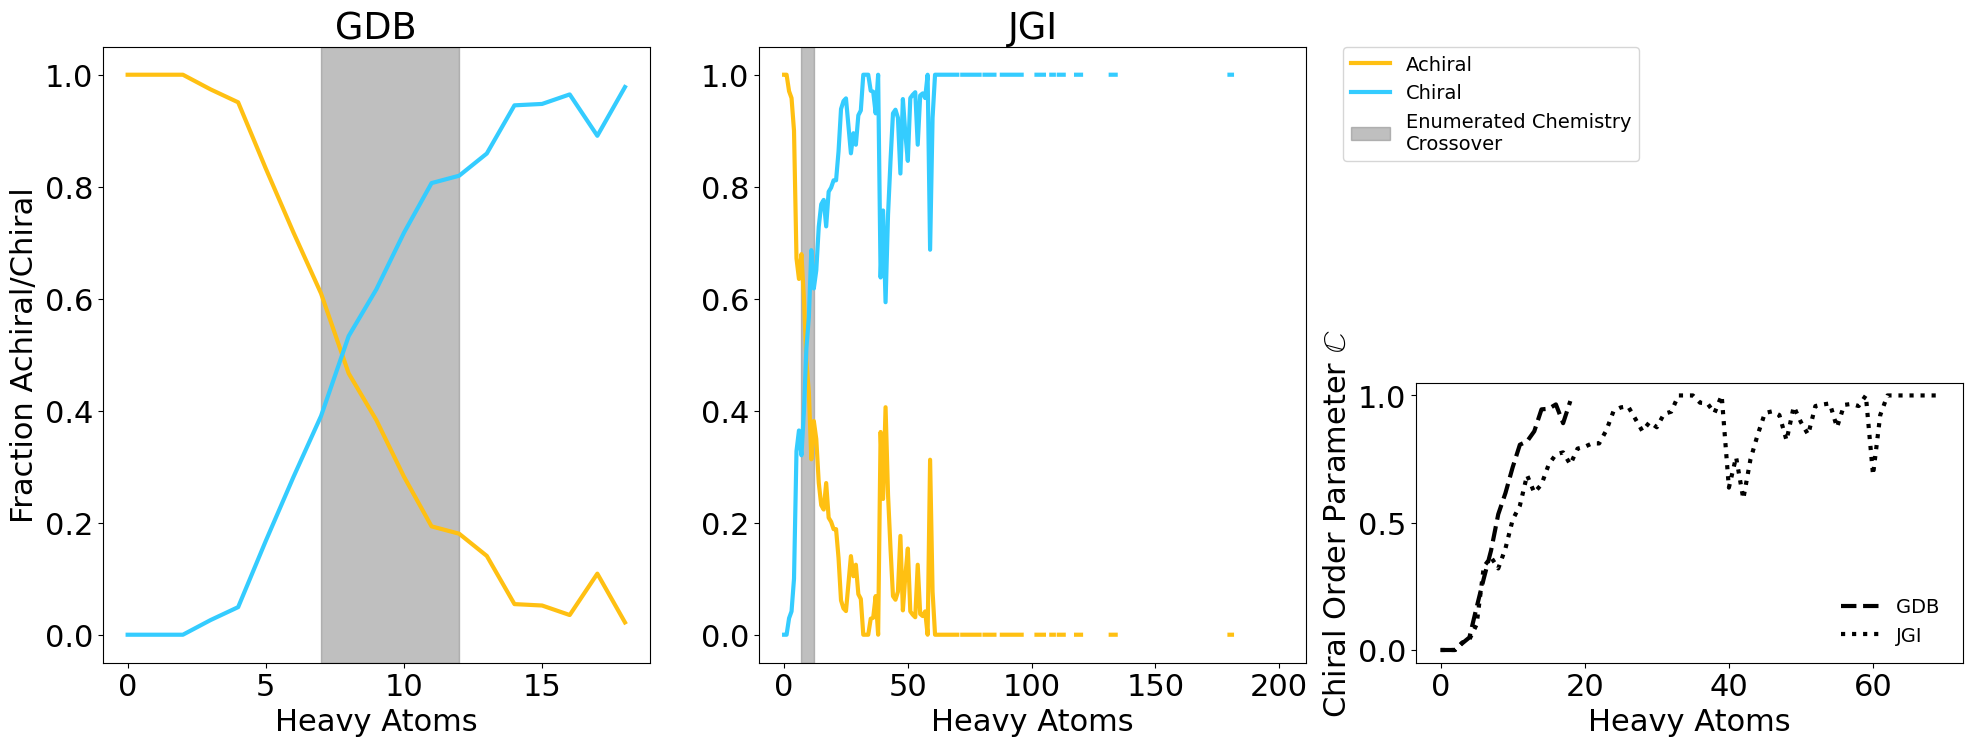

In [34]:
import matplotlib.gridspec as gridspec

plt.rcParams['figure.constrained_layout.use'] = False

plt.figure(figsize=(24,8))

gs = gridspec.GridSpec(2,6)

ax1 = plt.subplot(gs[:,0:2])

ax1.plot(gdb_df["fraction_achiral"], linewidth=3, label="Achiral", color=achiral_color)
ax1.plot(gdb_df["fraction_chiral"], linewidth=3, label="Chiral", color=chiral_color)

ax1.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

#ax1.legend(prop={"size":14})

#ax1.set_xlim(0,16)
ax1.set_ylim(-0.05, 1.05)
ax1.set_xlabel("Heavy Atoms")
ax1.set_ylabel("Fraction Achiral/Chiral")
ax1.set_title("GDB")


ax2 = plt.subplot(gs[:,2:4])

ax2.plot(all_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax2.plot(all_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

ax2.axvspan(7, 12, alpha=0.5, color='grey', label="Enumerated Chemistry\nCrossover")

ax2.legend(prop={"size":14}, bbox_to_anchor=(1.05, 1.015))

#ax2.set_xlim(0,16)
ax2.set_ylim(-0.05, 1.05)
ax2.set_xlabel("Heavy Atoms")
#ax2.set_ylabel("Fraction Achiral/Chiral")
ax2.set_title("JGI")

ax3 = plt.subplot(gs[1,4:])
ax3.plot(gdb_cop, linewidth=3, label="GDB ", color="k", linestyle="--")
ax3.plot(JGI_cop, linewidth=3, label="JGI", color="k", linestyle=":")

ax3.legend(frameon=False, prop={"size":14})
#ax3.set_xlim(0,16)
ax3.set_ylim(-0.05, 1.05)
ax3.set_xlabel("Heavy Atoms")
ax3.set_ylabel("Chiral Order Parameter $\mathbb{C}$")

ax3.annotate(xy=(150,0.4), text=r"$\mathbb{C} = \frac{C}{C+A}$", )

plt.subplots_adjust(wspace=0.5)

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

# Network Expansion

## Primordial Expansions

In [98]:
def process_expansion(fpath):
  with open(fpath) as f:
    #load file and create a dataframe called "generations"
    datajson = json.load(f)
    generations = pd.DataFrame(datajson["generations"])
    generations = generations.transpose()
    generations.index = generations.index.astype(int)
    generations = generations.sort_index()
    original_columns = generations.columns

    #Add n columns
    for col in original_columns:
        generations["n_"+col] = generations[col].str.len() 

    return generations
  

#Number of chiral/achiral compounds at each expansion step FOR LUCA
def get_chirality(generations, cpd_ccs):
  num_chiral = []
  num_achiral = []

  for index, row in generations.iterrows():
    chiral_count = 0
    achiral_count = 0
    for cpd in row["compounds_new"]:
      try:
        if cpd_ccs[cpd] == 0:
          achiral_count += 1
        else:
          chiral_count += 1
      except:
        pass
    num_chiral.append(chiral_count)
    num_achiral.append(achiral_count)

  return num_chiral, num_achiral

In [99]:
# Read in chiral labels of KEGG compounds. Contains KEGG cpd ID, SMILES string, & number of chiral centers
fp = "../Data/chiral_labels.csv"
chiral_df = pd.read_csv(fp)
chiral_df.head()

#make compound: num chiral centers dictionary
cpd_ccs = dict(zip(chiral_df.Cpd, chiral_df.Chiral_Centers))

In [100]:
#Run network expansion processing
fpath = "../Data/luca_expansion.json"
luca_generations = process_expansion(fpath)
luca_chiral, luca_achiral = get_chirality(luca_generations, cpd_ccs)

fpath = "../Data/primordial.dat0.json"
primordial_generations = process_expansion(fpath)
primordial_chiral, primordial_achiral = get_chirality(primordial_generations, cpd_ccs)
print(f"Number of steps in primordial expansion: {len(primordial_chiral)}")

Number of steps in primordial expansion: 46


In [101]:
chiral_color = "#34CCFF"
achiral_color = "#FFC012"
sum_color = "limegreen"

Final primordial chiral count: 2896
Final primordial achiral count: 1947


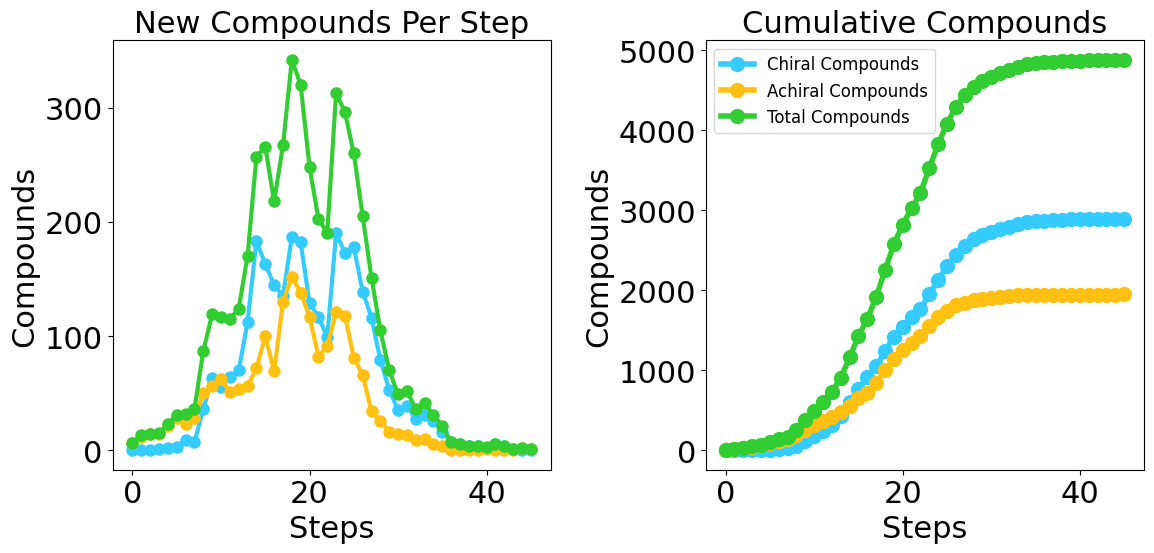

In [102]:
### Primordial Expansion plots
plt.figure(figsize=(12,6))
gs = gridspec.GridSpec(1,2)

# Plotting by new compounds
ax1 = plt.subplot(gs[0,0])

ax1.plot(primordial_chiral, color=chiral_color, marker="o", linewidth=3, markersize=8,
         label="Chiral Compounds",)
ax1.plot(primordial_achiral,  color=achiral_color, marker="o", linewidth=3, markersize=8,
         label="Achiral Compounds")
ax1.plot(np.arange(0, len(primordial_chiral), 1), primordial_generations["n_compounds_new"],
         color=sum_color, marker="o", linewidth=3, markersize=8, label="Total New Compounds")

#ax1.legend(facecolor="white", prop={"size": 12})
ax1.set_xlabel("Steps", fontsize=22)
ax1.set_ylabel("Compounds", fontsize=22)
ax1.set_title("New Compounds Per Step", fontsize=22)

#Cumulative plot
cum_num_chiral = np.cumsum(primordial_chiral)
cum_num_achiral = np.cumsum(primordial_achiral)

print(f"Final primordial chiral count: {cum_num_chiral[-1]}")
print(f"Final primordial achiral count: {cum_num_achiral[-1]}")

ax2 = plt.subplot(gs[0,1])
ax2.plot(cum_num_chiral, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Compounds",)
ax2.plot(cum_num_achiral,  color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Compounds")
ax2.plot(np.arange(0, len(primordial_chiral), 1), primordial_generations["n_compounds_cumulative"],
         color=sum_color, marker="o", linewidth=4, markersize=10, label="Total Compounds")

ax2.legend(facecolor="white", prop={"size": 12})
ax2.set_xlabel("Steps", fontsize=22)
ax2.set_ylabel("Compounds", fontsize=22)
ax2.set_title("Cumulative Compounds", fontsize=22)

plt.tight_layout()

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

## Random Seed Set Expansions

In [103]:
chiral_color = "#34CCFF"
achiral_color = "#FFC012"
mixed_color = "green"

df = pd.read_csv("../Data/scopes.csv")
print(df.head())

#Split dataframe into component labels (achiral, chiral, mix)
achiral_df = df[df["label"].str.match("achiral")]
chiral_df = df[df["label"].str.match("chiral")]
mix_df = df[df["label"].str.match("mix")]

   Unnamed: 0      label  avg_cpd_scope  avg_rxn_scope  \
0           0  achiral_2        165.551        229.254   
1           1  achiral_3        197.800        272.232   
2           2  achiral_4        385.137        534.633   
3           3  achiral_5        477.646        663.033   
4           4  achiral_6        558.059        773.855   

                                       all_cpd_scope  \
0  [1, 0, 4894, 0, 0, 1, 245, 0, 4879, 1, 1, 0, 0...   
1  [1, 4, 0, 4, 227, 40, 1, 0, 1, 0, 1, 1, 226, 1...   
2  [0, 260, 2, 1, 1, 0, 0, 2, 2, 1, 1, 1, 6, 4879...   
3  [4879, 9, 2, 3, 0, 227, 6, 0, 2, 2, 1, 1, 2, 4...   
4  [4, 228, 3, 2, 1, 245, 3, 7, 1, 13, 2, 14, 487...   

                                       all_rxn_scope      cpd_std      rxn_std  
0  [0, 0, 6872, 0, 0, 0, 263, 0, 6858, 0, 0, 0, 0...   858.188997  1206.358257  
1  [0, 3, 0, 2, 263, 41, 0, 0, 0, 0, 0, 0, 263, 0...   920.081402  1293.313101  
2  [0, 297, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 6858...  1282.761099  1803

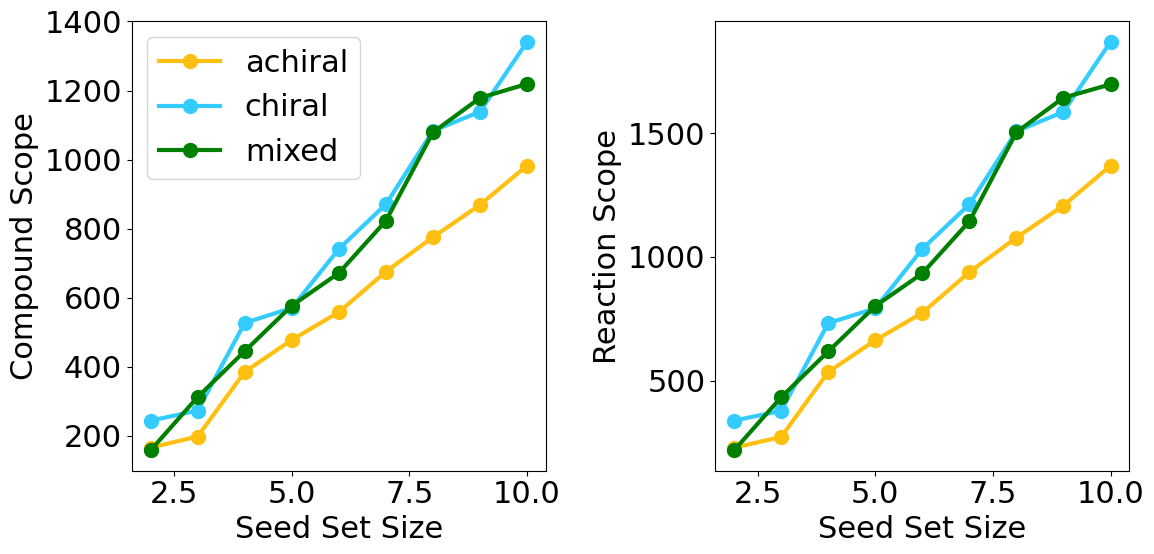

In [104]:

plt.figure(figsize=(12,6))
gs = gridspec.GridSpec(1,2)

## Cpd scope
ax1 = plt.subplot(gs[0,0])
ax1.plot(np.arange(2,11,1), achiral_df["avg_cpd_scope"], color=achiral_color, label="achiral", 
         marker="o", linewidth=3, markersize=10)
ax1.plot(np.arange(2,11,1), chiral_df["avg_cpd_scope"], color=chiral_color, label="chiral", 
         marker="o", linewidth=3, markersize=10)
ax1.plot(np.arange(2,11,1), mix_df["avg_cpd_scope"], color=mixed_color, label="mixed", 
         marker="o", linewidth=3, markersize=10)

ax1.legend()
ax1.set_xlabel("Seed Set Size")
ax1.set_ylabel("Compound Scope")


## Rxn scope
ax2 = plt.subplot(gs[0,1])
ax2.plot(np.arange(2,11,1), achiral_df["avg_rxn_scope"], color=achiral_color, label="achiral", 
         marker="o", linewidth=3, markersize=10)
ax2.plot(np.arange(2,11,1), chiral_df["avg_rxn_scope"], color=chiral_color, label="chiral", 
         marker="o", linewidth=3, markersize=10)
ax2.plot(np.arange(2,11,1), mix_df["avg_rxn_scope"], color=mixed_color, label="mixed", 
         marker="o", linewidth=3, markersize=10)

#ax2.legend()
ax2.set_xlabel("Seed Set Size")
ax2.set_ylabel("Reaction Scope")

plt.tight_layout()

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

In [105]:
def ridgeline_plots(df, l):
  #Convert dataframes into appropriate style
  df_ridgeline = pd.DataFrame(columns=["c", "n"])

  for index, row in df.iterrows():
    scopes = eval(row["all_cpd_scope"])
    for s in tqdm(scopes):
      df_ridgeline = df_ridgeline.append({"c": row["label"].split("_")[1], "n": s}, ignore_index=True)

  #find the log of each expansion
  df_ridgeline["n"] = pd.to_numeric(df_ridgeline["n"])
  with np.errstate(divide='ignore'):
      df_ridgeline["n"] = np.log(df_ridgeline["n"]) #.apply(np.log())
  #print(df)

  sns.set(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})
  #sns.set(font_scale = 1)

  #color palette (first number is the number of rows in the plot)
  pal = sns.cubehelix_palette(9, rot=1, light=0.9) 

  #Grid graphing
  grid = sns.FacetGrid(df_ridgeline, row="c", hue="c", aspect=15, height=1, palette=pal)

  #grid setup
  grid.map(sns.kdeplot, "n", clip_on=False, shade=True, alpha=1, lw=1.5, bw_method=.2)
  grid.map(sns.kdeplot, "n", clip_on=False, color="w", lw=2, bw_method=.2)
  grid.map(plt.axhline, y=0, lw=2, clip_on=False)

  # Define and use a simple function to label the plot in axes coordinates
  def label(x, color, label):
      ax = plt.gca()
      ax.text(0, .2, label, size=20, fontweight="bold", color=color,
              ha="left", va="center", transform=ax.transAxes)
      
  grid.map(label, "n")

  # Set the subplots to overlap
  grid.fig.subplots_adjust(hspace=-.25)

  # Remove axes details that don't play well with overlap
  grid.set_titles("")
  grid.set_ylabels("")
  grid.set(yticks=[])
  grid.despine(bottom=True, left=True)
  # grid.tick_params(labelsize=16)

  plt.title("Expanded Network Distribution: " + l, pad=500, fontweight="bold", size=30)
  plt.ylabel("Seed Set Size", labelpad=20, position=(0,20), size=20)
  plt.xlabel("Log of expanded network size", size=20)

100%|██████████| 1000/1000 [00:01<00:00, 574.75it/s]


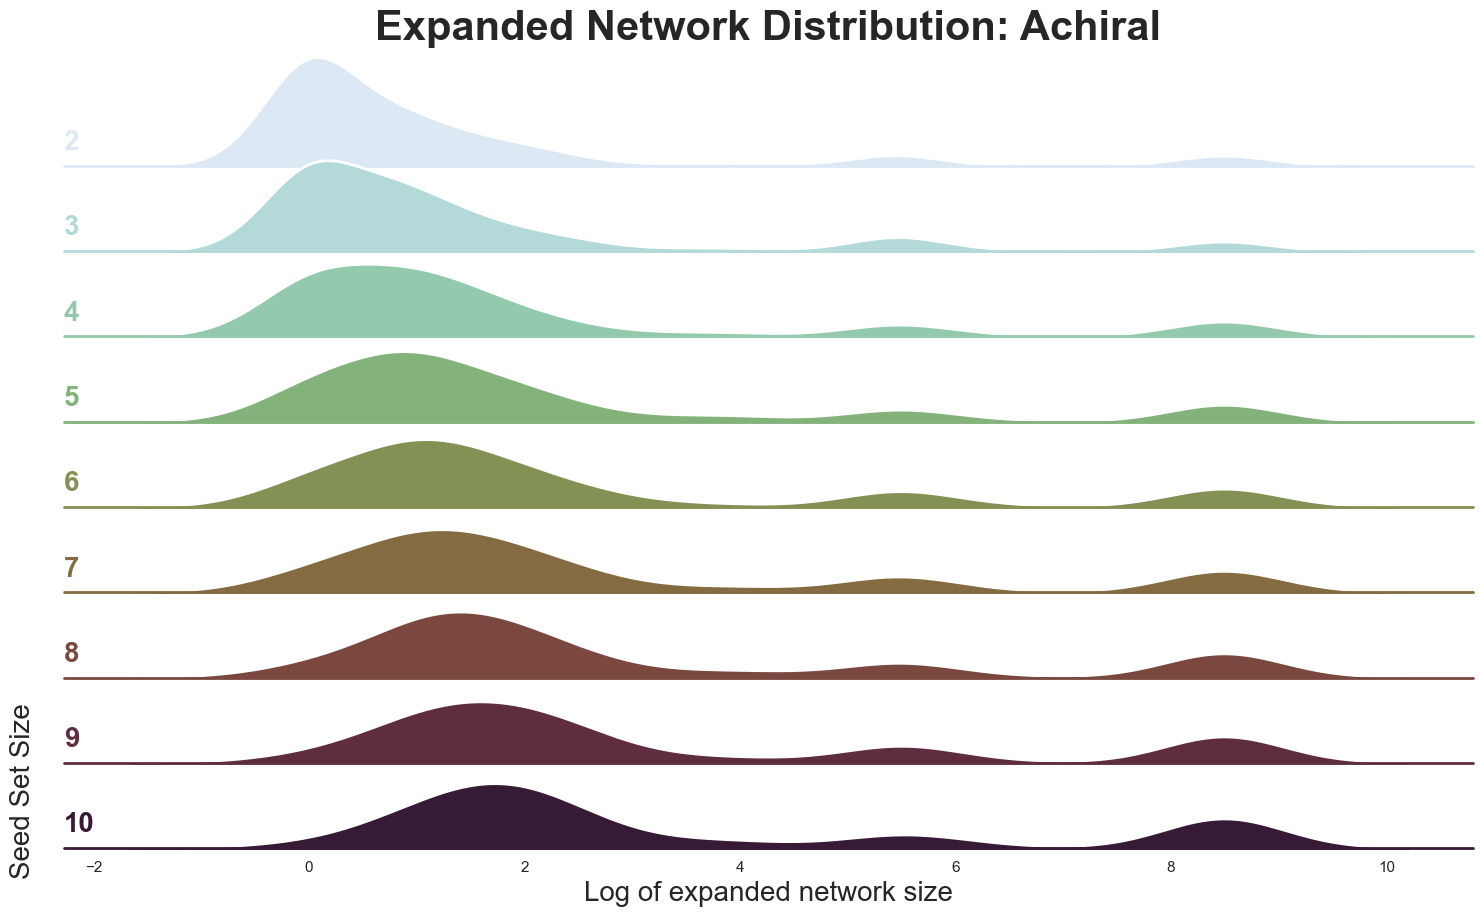

In [106]:
ridgeline_plots(achiral_df, "Achiral")

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

100%|██████████| 1000/1000 [00:01<00:00, 603.12it/s]


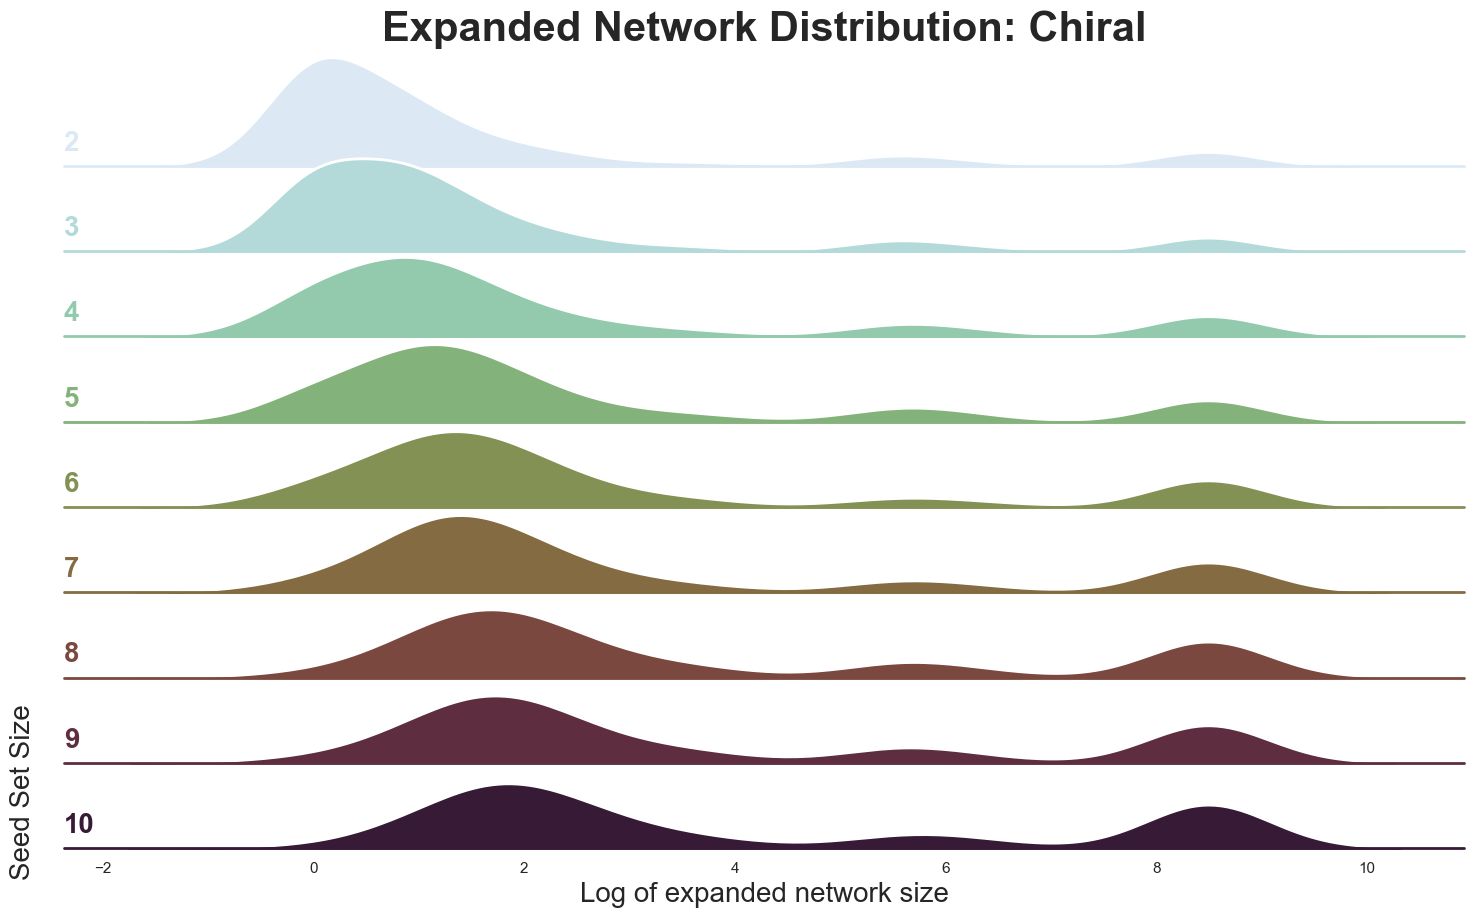

In [107]:
ridgeline_plots(chiral_df, "Chiral")
plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

100%|██████████| 1000/1000 [00:01<00:00, 577.34it/s]


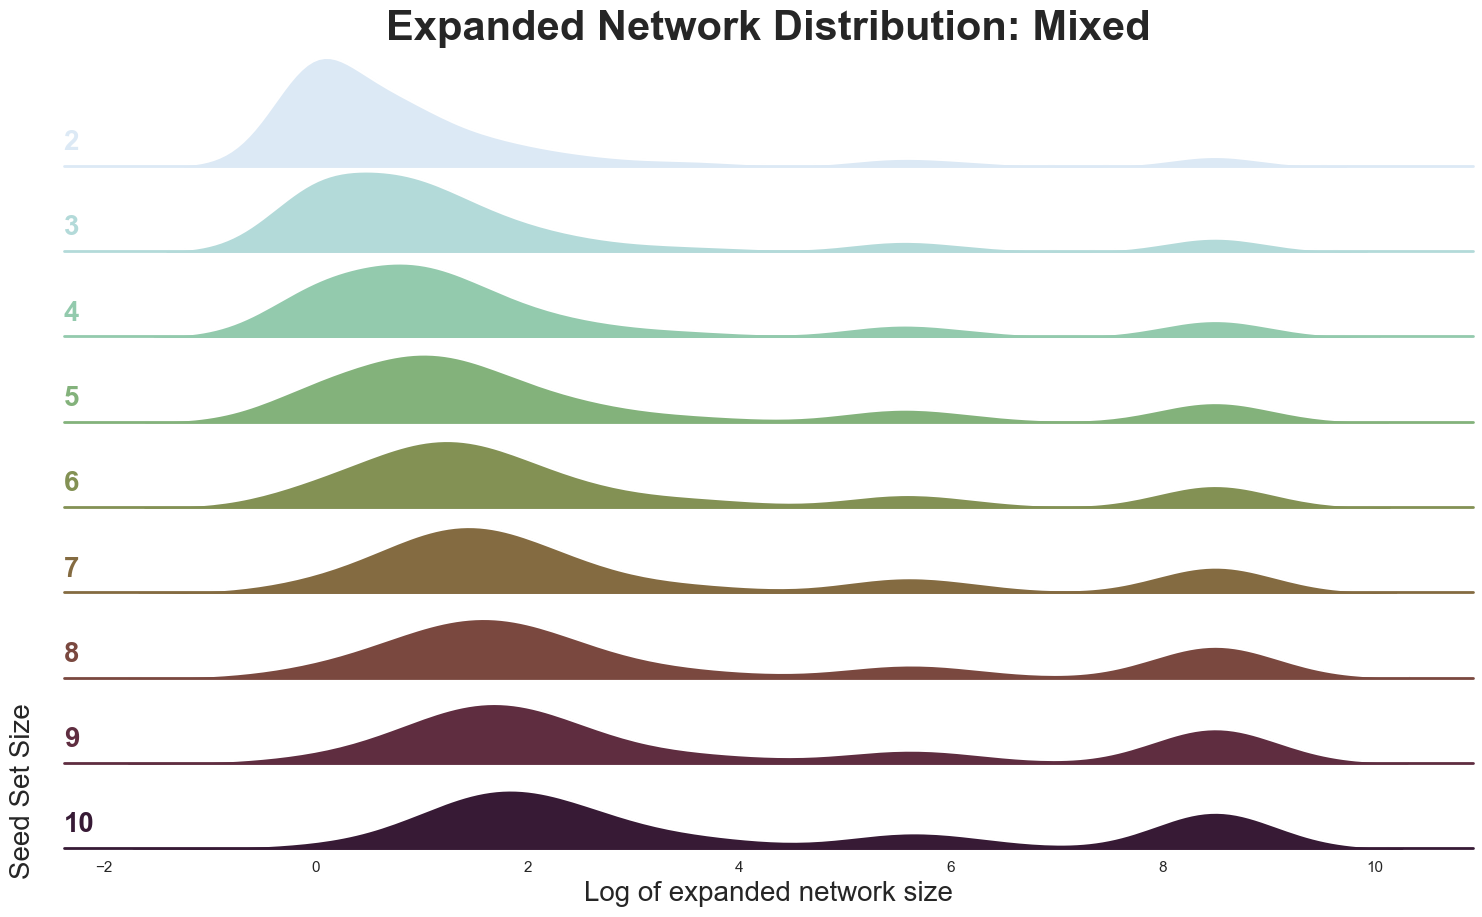

In [108]:
ridgeline_plots(mix_df, "Mixed")
plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

In [109]:
import matplotlib

matplotlib.rc_file_defaults()

font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rcParams.update({'font.size': 22})

In [110]:
def get_percentage(cum_chiral, cum_achiral):
    """ Get percentage chiral at a specific location

    Args:
        cum_chiral (list): cumulative sum of chiral compounds over generations
        cum_achiral (list): cumulative sum of achiral compounds over generations
    """
    chiral_percent = []
    for i in range(len(cum_chiral)):
        chiral_percent.append( float(cum_chiral[i]) / (cum_chiral[i] + cum_achiral[i]) )

    return chiral_percent
    

In [111]:
#Get statistics from pickle files (from expansion_analysis.py)
achiral_achiral_sizes = pickle.load(file=open("../Data/achiral_achiral_sizes.p", "rb"))
achiral_chiral_sizes = pickle.load(file=open("../Data/achiral_chiral_sizes.p", "rb"))

chiral_achiral_sizes = pickle.load(file=open("../Data/chiral_achiral_sizes.p", "rb"))
chiral_chiral_sizes = pickle.load(file=open("../Data/chiral_chiral_sizes.p", "rb"))

achiral_chiralPercentage = []
chiral_chiralPercentage = []

for i in range(len(achiral_chiral_sizes)):
    achiral_chiralPercentage.append(get_percentage(np.cumsum(achiral_chiral_sizes[i]), np.cumsum(achiral_achiral_sizes[i])))

for i in range(len(chiral_chiral_sizes)):
    chiral_chiralPercentage.append(get_percentage(np.cumsum(chiral_chiral_sizes[i]), np.cumsum(chiral_achiral_sizes[i])))

print(achiral_chiralPercentage[0])

# print(combined_achiral_luca_percents)

achiral_avg_percentages_chiral = []
achiral_std_percentages_chiral = []

chiral_avg_percentages_chiral = []
chiral_std_percentages_chiral = []


for i in tqdm(range(100)): #100 steps is larger than any other expansion
    percentages = [] 
    for result in achiral_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])

    achiral_avg_percentages_chiral.append(np.mean(percentages))
    achiral_std_percentages_chiral.append(np.std(percentages))

    percentages = [] 
    for result in chiral_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])

    chiral_avg_percentages_chiral.append(np.mean(percentages))
    chiral_std_percentages_chiral.append(np.std(percentages))

print(chiral_avg_percentages_chiral)
print(chiral_std_percentages_chiral)

/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:10: RuntimeWarning: invalid value encountered in true_divide
  # Remove the CWD from sys.path while we load stuff.


[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.02857142857142857, 0.05263157894736842, 0.05128205128205128, 0.05434782608695652, 0.13675213675213677, 0.2214765100671141, 0.26229508196721313, 0.25980392156862747, 0.2636363636363636, 0.2683982683982684, 0.2782258064516129, 0.31076923076923074, 0.3226600985221675, 0.3177966101694915, 0.3156934306569343, 0.345679012345679, 0.35618279569892475, 0.3593556381660471, 0.3614864864864865, 0.4111431316042267, 0.43976411120471776, 0.46248085758039814, 0.49375866851595007, 0.5133214920071048, 0.5330210772833723, 0.5389197776012709, 0.5422939068100359, 0.5471760797342192, 0.5483468496568933, 0.5499707773232028, 0.5539094650205761, 0.5650623885918004, 0.5679012345679012, 0.575046468401487, 0.5803470813612801, 0.5844385499557914, 0.5873015873015873, 0.5893968662803176, 0.5902023429179979, 0.5915136162127929, 0.592918499895244, 0.5939192003331945, 0.5950207468879668, 0.5957755228825844, 0.5961100765570039, 0.5964440769071738, 0.5964876033057851, 0.5969040247678019, 

 55%|█████▌    | 55/100 [00:00<00:00, 542.37it/s]/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:223: RuntimeWarning: invalid value encountered in true_divide
  subok=False)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:254: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
100%

[nan, 0.7780236118956286, 0.6856863728777924, 0.6079523593475042, 0.5472074343076272, 0.5056637172671706, 0.474724236769888, 0.45947166973485215, 0.45442417559956555, 0.45184449623906314, 0.4548454212763454, 0.4595730231687197, 0.4631541978546751, 0.46844626106984205, 0.47292734678670834, 0.4789298387494313, 0.48556273951214757, 0.4920165320848122, 0.4981864863929961, 0.5037218809895034, 0.5097597009025127, 0.5214508347990737, 0.5290693331330097, 0.5349508307475944, 0.5386537223708538, 0.5430267576732429, 0.5496036491548612, 0.5553342929122707, 0.5601562823332477, 0.5644685493385448, 0.5671998404929722, 0.5797013413688954, 0.5871595510408268, 0.589372279088371, 0.5909844789651598, 0.593337234026269, 0.5944470102097725, 0.5952949263414272, 0.5960232715695866, 0.5966014651848378, 0.5971590105683945, 0.597557640747484, 0.5979239943200901, 0.5982162266381402, 0.5984833703745958, 0.598703885631627, 0.5987760045737318, 0.5988357305693669, 0.5989826807976599, 0.5990819630175113, 0.59913042274

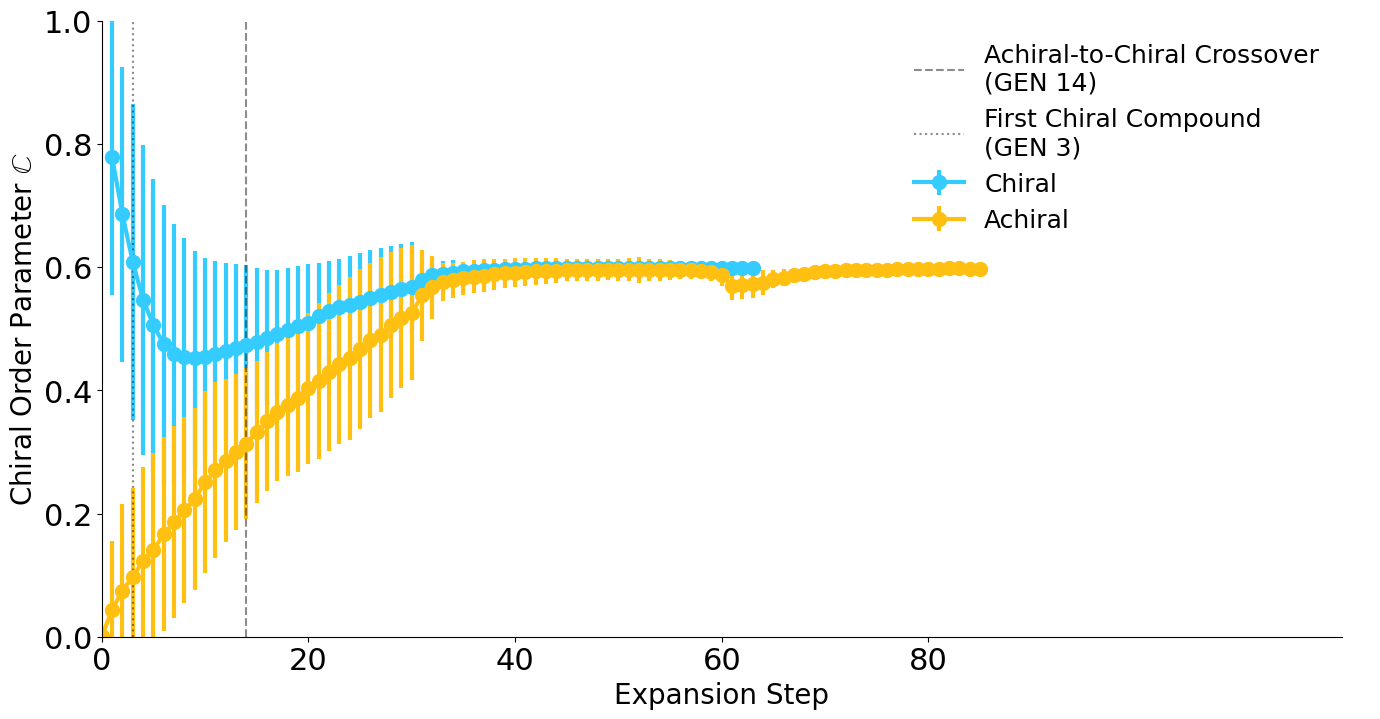

In [112]:
fig, ax = plt.subplots(figsize=(16,8))

#Chiral
ax.errorbar(x=np.arange(0, len(chiral_avg_percentages_chiral), 1), y=chiral_avg_percentages_chiral, 
             yerr=chiral_std_percentages_chiral, color=chiral_color, marker="o", linewidth=3, 
             markersize=10, label="Chiral")

## Achiral
ax.errorbar(x=np.arange(0, len(achiral_avg_percentages_chiral), 1), y=achiral_avg_percentages_chiral, 
             yerr=achiral_std_percentages_chiral, color=achiral_color, marker="o", linewidth=3, 
             markersize=10, label="Achiral")

ax.axvline(x=14, color="k", linestyle="--", alpha=0.5, label="Achiral-to-Chiral Crossover\n(GEN 14)")
ax.axvline(x=3, color="k", linestyle=":", alpha=0.5, label="First Chiral Compound\n(GEN 3)")

ax.set_ylim([0,1])
ax.set_xlim([0,120]) #csm - changed from 98

#Remove 100 & 120 from xticks
ax_xticks = ax.xaxis.get_major_ticks()
ax_xticks[-1].set_visible(False)
ax_xticks[-2].set_visible(False)

#Remove top & right ax3 borders to make legend more obviously connected to the rest of the plot
ax.spines[['right', 'top']].set_visible(False)

ax.set_xlabel("Expansion Step", fontsize=20)
ax.set_ylabel("Chiral Order Parameter $\mathbb{C}$", fontsize=20)
lgd = ax.legend(prop={"size": 18}, frameon=False, loc="upper right") #, bbox_to_anchor=(1.1,0.95))

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

## LUCA Expansions

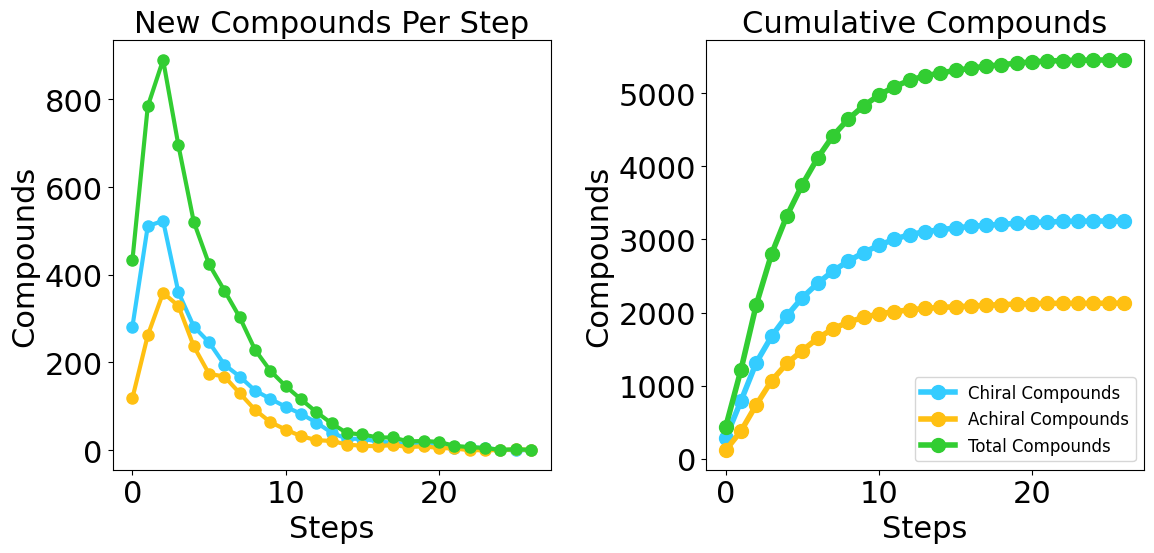

In [113]:
### LUCA Expansion plots
plt.figure(figsize=(12,6))
gs = gridspec.GridSpec(1,2)

# Plotting by new compounds
ax1 = plt.subplot(gs[0,0])

ax1.plot(luca_chiral, color=chiral_color, marker="o", linewidth=3, markersize=8,
         label="Chiral Compounds",)
ax1.plot(luca_achiral,  color=achiral_color, marker="o", linewidth=3, markersize=8,
         label="Achiral Compounds")
ax1.plot(np.arange(0, len(luca_chiral), 1), luca_generations["n_compounds_new"],
         color=sum_color, marker="o", linewidth=3, markersize=8, label="Total New Compounds")

#ax1.legend(facecolor="white", prop={"size": 12})
ax1.set_xlabel("Steps", fontsize=22)
ax1.set_ylabel("Compounds", fontsize=22)
ax1.set_title("New Compounds Per Step", fontsize=22)

#Cumulative plot
cum_num_chiral = np.cumsum(luca_chiral)
cum_num_achiral = np.cumsum(luca_achiral)

ax2 = plt.subplot(gs[0,1])
ax2.plot(cum_num_chiral, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Compounds",)
ax2.plot(cum_num_achiral,  color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Compounds")
ax2.plot(np.arange(0, len(luca_chiral), 1), luca_generations["n_compounds_cumulative"],
         color=sum_color, marker="o", linewidth=4, markersize=10, label="Total Compounds")

ax2.legend(facecolor="white", prop={"size": 12})
ax2.set_xlabel("Steps", fontsize=22)
ax2.set_ylabel("Compounds", fontsize=22)
ax2.set_title("Cumulative Compounds", fontsize=22)

plt.tight_layout()
plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

# Pathways

In [114]:
fp = "../Data/pathway_appearences.csv"
df = pd.read_csv(fp)
print(df.head())
print(len(df))

   Pathway  Size  Chirality  Timestep  Not_Appear  Percent_Appear  \
0      720    51   0.470588        22           0        1.000000   
1     1059    67   0.686567         0          30        0.552239   
2      410    32   0.437500        18           0        1.000000   
3      680    92   0.565217         0          15        0.836957   
4      920    48   0.291667         0           1        0.979167   

   Max_Appearence_Timestep  Chirality_Max_Appearence  
0                       22                  0.550116  
1                       32                  0.586339  
2                       18                  0.548691  
3                       29                  0.580453  
4                       25                  0.555992  
154


In [115]:
#Find labels of each pathway
fp = "../Data/pathway_names.json"
with open(fp) as f:
  pathway_names = json.load(f)

#Find overall labels (overview) and specific (sub-class) labels
pathway_overview_names_dict = {}
pathway_specific_names_dict = {}
for key in pathway_names["children"]:
  #key["name"]) -> the overview names of the pathway classes
  for key2 in key["children"]:
    #key2["name"] -> specifc names of pathway classes
    for key3 in key2["children"]:
      specific_name = key3["name"][:5]
      pathway_overview_names_dict[int(specific_name)] = key["name"]
      pathway_specific_names_dict[int(specific_name)] = key2["name"]

print(pathway_overview_names_dict)

{1100: 'Metabolism', 1110: 'Metabolism', 1120: 'Metabolism', 1200: 'Metabolism', 1210: 'Metabolism', 1212: 'Metabolism', 1230: 'Metabolism', 1220: 'Metabolism', 10: 'Metabolism', 20: 'Metabolism', 30: 'Metabolism', 40: 'Metabolism', 51: 'Metabolism', 52: 'Metabolism', 53: 'Metabolism', 500: 'Metabolism', 520: 'Metabolism', 620: 'Metabolism', 630: 'Metabolism', 640: 'Metabolism', 650: 'Metabolism', 660: 'Metabolism', 562: 'Metabolism', 190: 'Metabolism', 195: 'Metabolism', 196: 'Metabolism', 710: 'Metabolism', 720: 'Metabolism', 680: 'Metabolism', 910: 'Metabolism', 920: 'Metabolism', 61: 'Metabolism', 62: 'Metabolism', 71: 'Metabolism', 72: 'Metabolism', 73: 'Metabolism', 100: 'Metabolism', 120: 'Metabolism', 121: 'Metabolism', 140: 'Metabolism', 561: 'Metabolism', 564: 'Metabolism', 565: 'Metabolism', 600: 'Metabolism', 590: 'Metabolism', 591: 'Metabolism', 592: 'Metabolism', 1040: 'Metabolism', 230: 'Metabolism', 240: 'Metabolism', 250: 'Metabolism', 260: 'Metabolism', 270: 'Metaboli

In [116]:
#Set up metabolic dataframe containing data only from metabolic pathways
metabolic_df = pd.DataFrame()

for index, row in df.iterrows():
  try:
    name = pathway_overview_names_dict[row["Pathway"]]
  except:
    name = ""

  if name == "Metabolism":
    metabolic_df = metabolic_df.append(row)

print(metabolic_df.head())
print(len(metabolic_df))

   Pathway  Size  Chirality  Timestep  Not_Appear  Percent_Appear  \
0    720.0  51.0   0.470588      22.0         0.0        1.000000   
1   1059.0  67.0   0.686567       0.0        30.0        0.552239   
2    410.0  32.0   0.437500      18.0         0.0        1.000000   
3    680.0  92.0   0.565217       0.0        15.0        0.836957   
4    920.0  48.0   0.291667       0.0         1.0        0.979167   

   Max_Appearence_Timestep  Chirality_Max_Appearence  
0                     22.0                  0.550116  
1                     32.0                  0.586339  
2                     18.0                  0.548691  
3                     29.0                  0.580453  
4                     25.0                  0.555992  
151


In [117]:
#Hardcoding metabolic pathway subgroup names & colors

metabolism_groups = {"Carbohydrate Metabolism": [10,20,30,40,51,52,53,500,520,620,630,640,650,660,562],
                     "Glycan Biosynthesis": [510,513,512,515,514,532,534,533,531,563,601,603,604,540,542,541,550,511,571,572],
                     "Terpenoids and Polyketides": [900,902,909,904,906,905,981,908,903,281,1052,522,1051,1059,1056,1057,253,523,1054,1053,1055],
                     "Lipid Metabolism": [61,62,71,73,100,120,121,140,561,564,565,600,590,591,592,1040],
                     "Secondary Metabolite Biosynthesis": [940,945,941,944,942,943,901,403,950,960,1058,232,965,966,402,311,332,261,331,521,524,525,401,404,405,333,254,999,998,997],
                     "Nucleotide Metabolism": [230,240],
                     "Amino Acid Metabolism": [250,260,270,280,290,300,310,220,330,340,350,360,380,400],
                     "Metabolism of Other Amino Acids": [410,430,440,450,460,470,480],
                     "Cofactors and Vitamins": [730,740,750,760,770,780,785,790,670,830,860,130],
                     "Energy Metabolism": [190,195,196,710,720,680,910,920],
                     "Xenobiotics": [362,627,364,625,361,623,622,633,642,643,791,930,363,621,626,624,365,984,980,982,983]}

colors = {"Carbohydrate Metabolism": "#aa0f35", 
          "Glycan Biosynthesis": "#487c7c", 
          "Terpenoids and Polyketides": "#009ecb", 
          "Lipid Metabolism": "#abdbfc", 
          "Secondary Metabolite Biosynthesis": "#430057", 
          "Nucleotide Metabolism": "#a0a75c", 
          "Amino Acid Metabolism": "#603734",
          "Metabolism of Other Amino Acids": "#d97e43", 
          "Cofactors and Vitamins": "#313a61", 
          "Energy Metabolism": "#fdc799",
          "Xenobiotics": "#f5c500"}

pathway_group_keys = {"Carbohydrate Metabolism": 1, 
          "Glycan Biosynthesis": 2, 
          "Terpenoids and Polyketides": 3, 
          "Lipid Metabolism": 4, 
          "Secondary Metabolite Biosynthesis": 5, 
          "Nucleotide Metabolism": 6, 
          "Amino Acid Metabolism": 7,
          "Metabolism of Other Amino Acids": 8, 
          "Cofactors and Vitamins": 9, 
          "Energy Metabolism": 10,
          "Xenobiotics": 11}

color_list = ["#aa0f35", 
          "#487c7c", 
          "#009ecb", 
          "#abdbfc", 
          "#430057", 
          "#a0a75c", 
          "#603734",
          "#d97e43", 
          "#fdc799",
          "#313a61", 
          "#f5c500"]

def set_box_color(bp, color):
  plt.setp(bp['boxes'], color=color)
  plt.setp(bp['whiskers'], color=color)
  plt.setp(bp['caps'], color=color)
  plt.setp(bp['medians'], color=color)

In [118]:
#Assign colors to all metabolic pathways
pathway_groups = {}
pathway_group_colors = {}
pathway_groups_list = []
pathway_key_list = []
pathway_colors = []

for _, row in metabolic_df.iterrows():
  found_group = 0
  for group, pathways in metabolism_groups.items():
    if int(row["Pathway"]) in pathways:
      pathway_groups[int(row["Pathway"])] = group
      pathway_group_colors[int(row["Pathway"])] = colors[group]
      pathway_groups_list.append(group)
      pathway_key_list.append(pathway_group_keys[group])
      pathway_colors.append(row["Pathway"])
      found_group = 1
  if not found_group:
    pathway_groups_list.append(np.NaN)
    pathway_key_list.append(np.NaN)
    pathway_colors.append(np.NaN)

print(pathway_groups)
print(pathway_group_colors)
metabolic_df["Group"] = pathway_groups_list
metabolic_df["Group Key"] = pathway_key_list
metabolic_df["Color"] = pathway_colors

#Setup for box & whisker plot - needs a 2d array of chiralities
chiralities = []
for group in colors.keys():
  chiralities.append(df[df['Pathway'].isin(metabolism_groups[group])]["Chirality"].tolist())

print(chiralities)

#Sort dataframe by a specific value
metabolic_df = metabolic_df.sort_values(by=["Chirality"])

{720: 'Energy Metabolism', 1059: 'Terpenoids and Polyketides', 410: 'Metabolism of Other Amino Acids', 680: 'Energy Metabolism', 920: 'Energy Metabolism', 600: 'Lipid Metabolism', 550: 'Glycan Biosynthesis', 311: 'Secondary Metabolite Biosynthesis', 310: 'Amino Acid Metabolism', 10: 'Carbohydrate Metabolism', 254: 'Secondary Metabolite Biosynthesis', 250: 'Amino Acid Metabolism', 253: 'Terpenoids and Polyketides', 540: 'Glycan Biosynthesis', 910: 'Energy Metabolism', 140: 'Lipid Metabolism', 750: 'Cofactors and Vitamins', 999: 'Secondary Metabolite Biosynthesis', 998: 'Secondary Metabolite Biosynthesis', 300: 'Amino Acid Metabolism', 20: 'Carbohydrate Metabolism', 380: 'Amino Acid Metabolism', 220: 'Amino Acid Metabolism', 904: 'Terpenoids and Polyketides', 905: 'Terpenoids and Polyketides', 906: 'Terpenoids and Polyketides', 900: 'Terpenoids and Polyketides', 901: 'Secondary Metabolite Biosynthesis', 902: 'Terpenoids and Polyketides', 903: 'Terpenoids and Polyketides', 908: 'Terpenoid

[20.0, 640.0, 630.0, 650.0, 620.0, 660.0, 10.0, 40.0, 53.0, 562.0, 51.0, 52.0, 30.0, 520.0, 500.0]
[0.391304347826087, 0.4583333333333333, 0.4923076923076923, 0.5238095238095238, 0.5483870967741935, 0.5588235294117647, 0.7096774193548387, 0.8909090909090909, 0.8979591836734694, 0.9361702127659576, 0.9464285714285714, 0.9583333333333334, 0.9736842105263158, 0.9829059829059827, 1.0]
[  0.  24.  48.  72. 276. 300. 324. 348. 372. 396. 420. 444. 288. 312.
 336.]
Text(0.0, 0, '20.0') 0.0
Text(0.4188790204786391, 0, '640.0') 24.0
Text(0.8377580409572782, 0, '630.0') 48.0
Text(1.2566370614359172, 0, '650.0') 72.0
Text(1.6755160819145565, 0, '620.0') 276.0
Text(2.0943951023931953, 0, '660.0') 299.99999999999994
Text(2.5132741228718345, 0, '10.0') 324.0
Text(2.9321531433504733, 0, '40.0') 348.0
Text(3.351032163829113, 0, '53.0') 371.99999999999994
Text(3.7699111843077517, 0, '562.0') 396.0
Text(4.1887902047863905, 0, '51.0') 420.0
Text(4.60766922526503, 0, '52.0') 443.99999999999994
Text(5.02654

/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:43: UserWarning: FixedFormatter should only be used together with FixedLocator


[  0.  24.  48.  72. 276. 300. 324. 348. 372. 396. 420. 444. 288. 312.
 336.]
Text(0.0, 0, '73.0') 0.0
Text(0.4188790204786391, 0, '61.0') 24.0
Text(0.8377580409572782, 0, '591.0') 48.0
Text(1.2566370614359172, 0, '592.0') 72.0
Text(1.6755160819145565, 0, '564.0') 276.0
Text(2.0943951023931953, 0, '561.0') 299.99999999999994
Text(2.5132741228718345, 0, '71.0') 324.0
Text(2.9321531433504733, 0, '565.0') 348.0
Text(3.351032163829113, 0, '590.0') 371.99999999999994
Text(3.7699111843077517, 0, '1040.0') 396.0
Text(4.1887902047863905, 0, '120.0') 420.0
Text(4.60766922526503, 0, '62.0') 443.99999999999994
Text(5.026548245743669, 0, '600.0') 288.0
Text(5.445427266222308, 0, '100.0') 312.0
Text(5.864306286700947, 0, '140.0') 335.99999999999994
[232.0, 1058.0, 333.0, 940.0, 402.0, 405.0, 966.0, 945.0, 943.0, 401.0, 404.0, 960.0, 944.0, 941.0, 950.0, 999.0, 332.0, 965.0, 998.0, 254.0, 901.0, 261.0, 403.0, 942.0, 524.0, 525.0, 521.0, 311.0, 331.0]
[0.0909090909090909, 0.1428571428571428, 0.222222

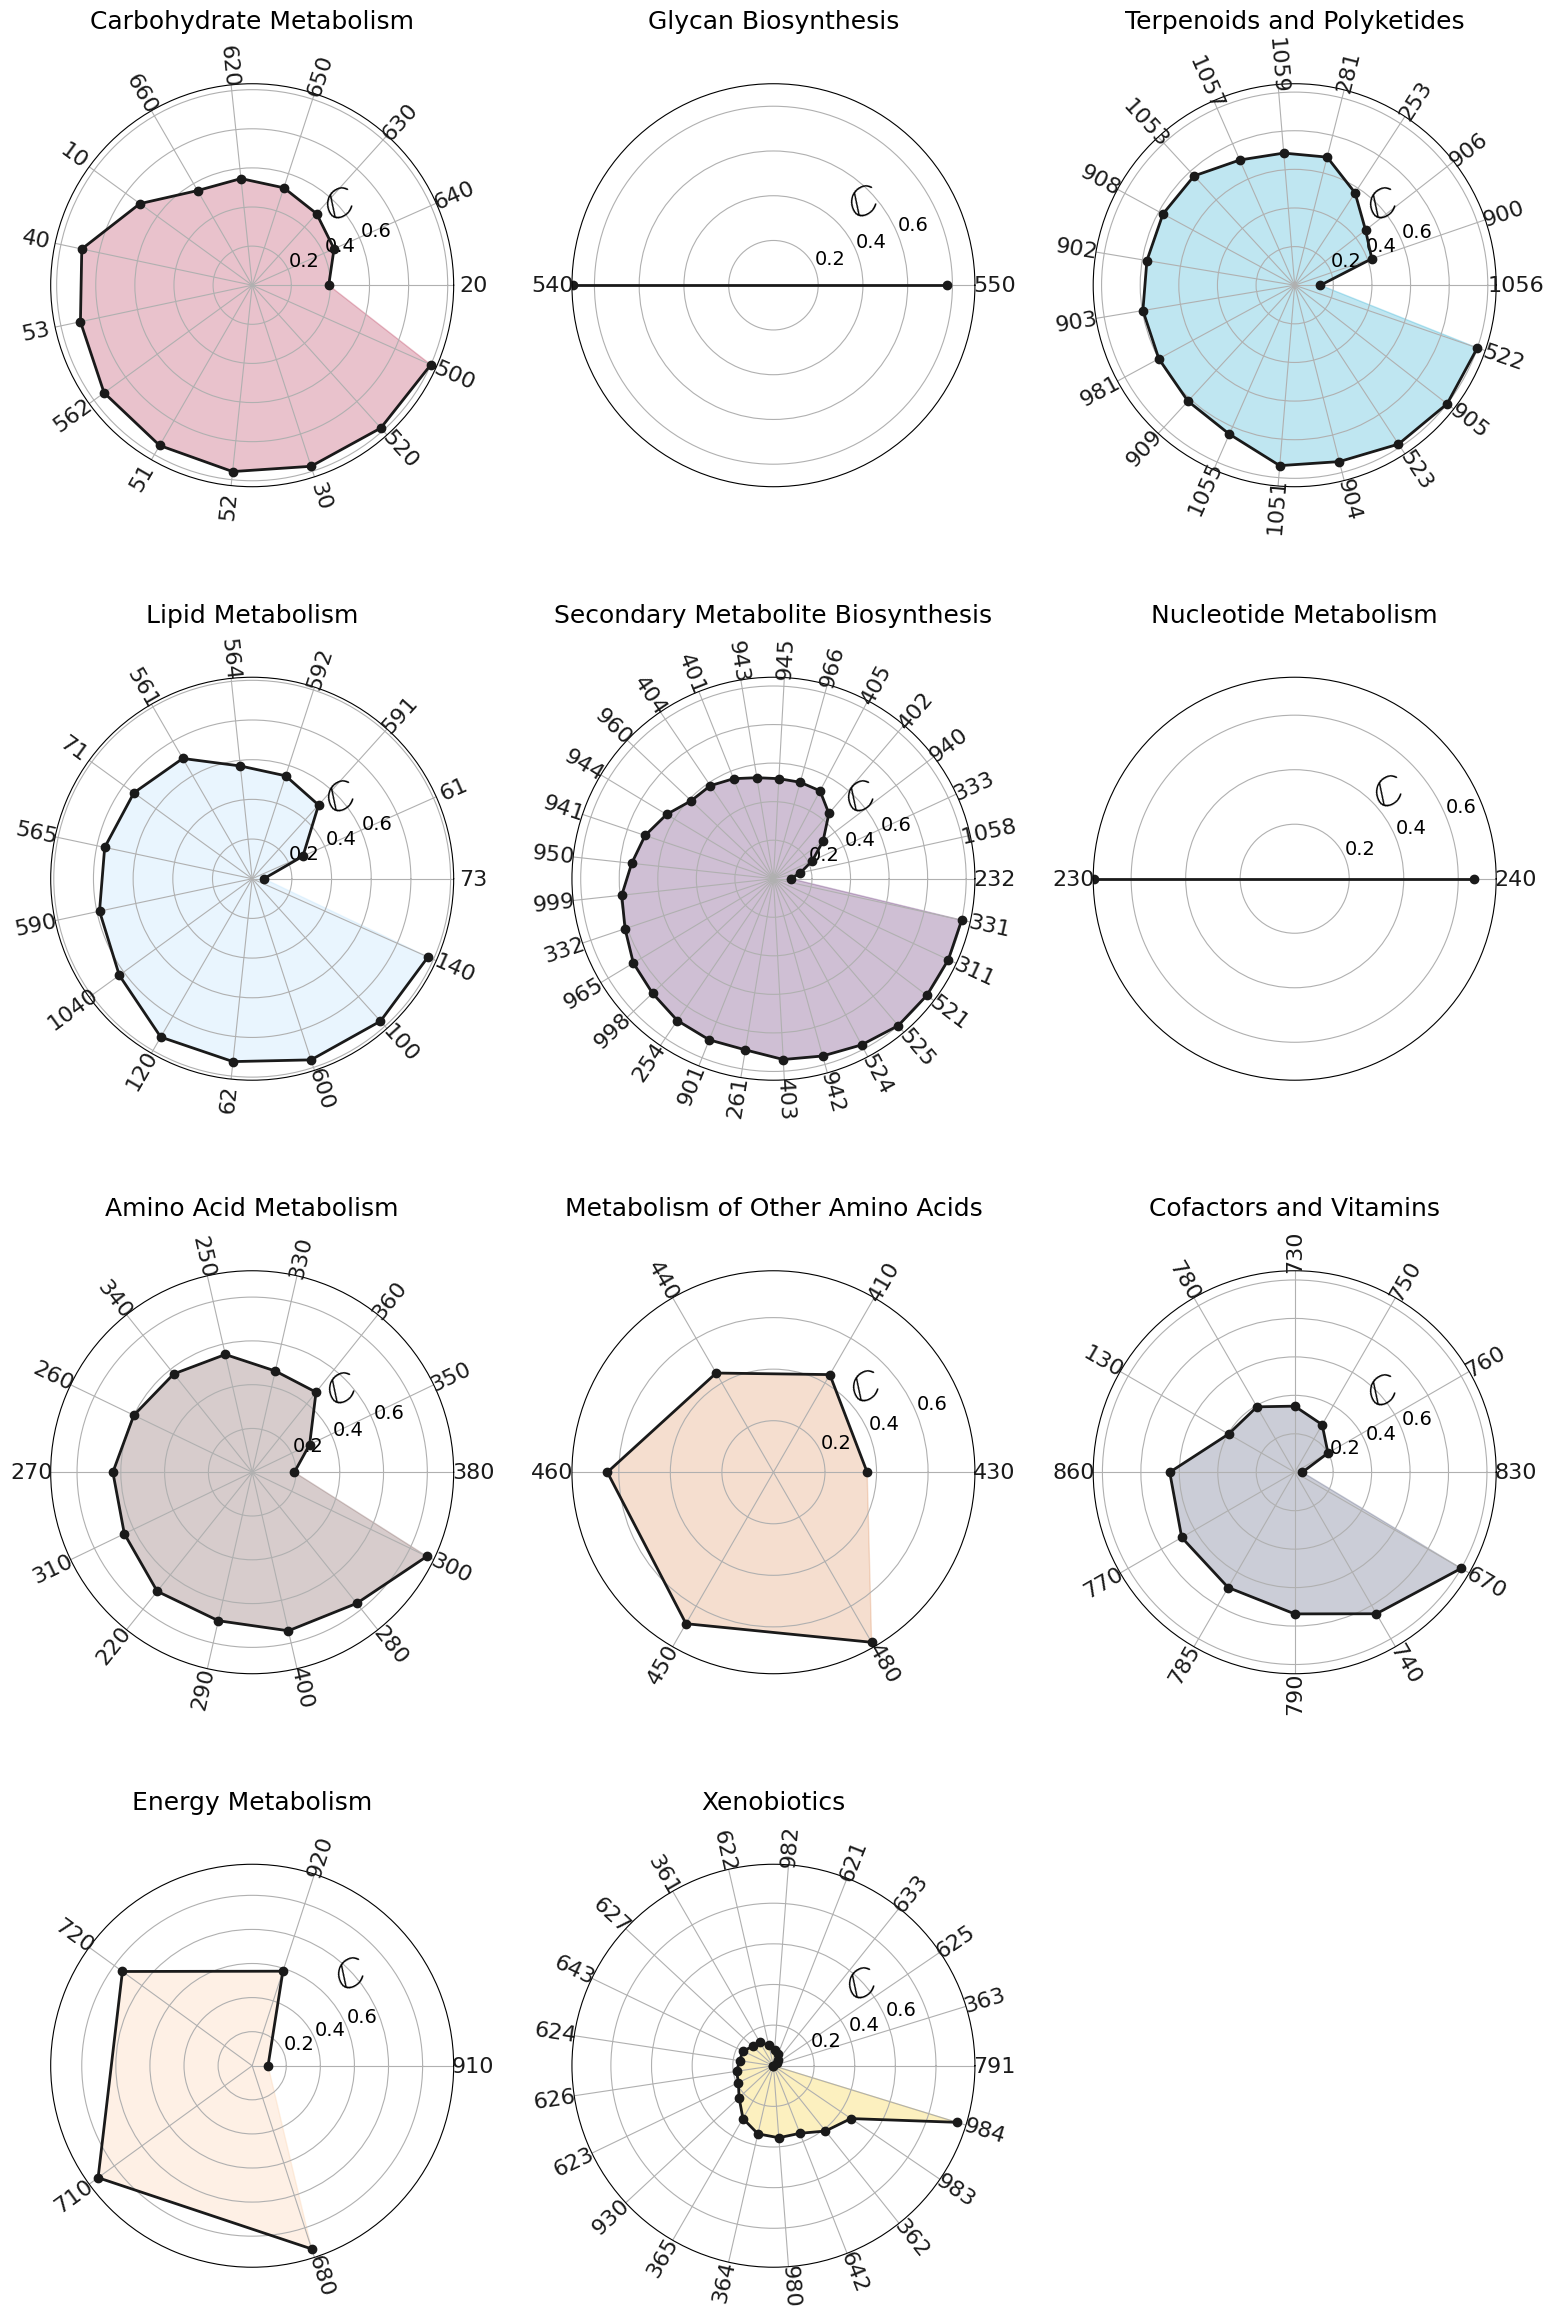

In [119]:
plt.figure(figsize=(16,24))
gs = gridspec.GridSpec(4,3)

xcount = 0
ycount = 0

for group in list(metabolism_groups.keys()):
  #Label with pathway number
  sub_df = metabolic_df[metabolic_df["Group"] == group]
  labels = sub_df['Pathway'].tolist()

  print(labels)

  #Define each angle for plotting
  angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)
  stats = sub_df['Chirality'].tolist()
  print(stats)

  ax = plt.subplot(gs[xcount,ycount], polar=True)
  #ax = fig.add_subplot(polar=True)
  ax.plot(angles, stats, 'o-', linewidth=2, color="k")
  ax.fill(angles, stats, alpha=0.25, color=colors[group])
  ax.set_thetagrids(angles * 180/np.pi, labels,)

  #Make all angles rotated according to placement on the image
  #plt.gca.canvas.draw()
  angles[np.cos(angles) < 0] = angles[np.cos(angles) < 0] + np.pi
  angles = np.rad2deg(angles)
  print(angles)
  for label, angle in zip(ax.get_xticklabels(), angles):
    print(label, angle)
    x,y = label.get_position()
    try:
      lab = ax.text(x, y, int(float(label.get_text())), transform=label.get_transform(), 
                  ha=label.get_ha(), va=label.get_va(), color="k",
                  fontsize=16)
    except:
      lab = ax.text(x, y, label.get_text(), transform=label.get_transform(), 
                  ha=label.get_ha(), va=label.get_va(), color='k', fontsize=14)
    lab.set_rotation(angle)
    labels.append(lab)
  ax.set_xticklabels([])
  ax.set_yticklabels(["0.2", "0.4", "0.6", "", ""], fontsize=14)

  #label chiral percentage 
  label_pos = ax.get_rlabel_position()
  ax.text(np.radians(label_pos+20), ax.get_rmax()/2. + 0.1, "$\mathbb{C}$",
          rotation=label_pos+4, ha='center', va='center', fontsize=30, weight="bold")
  ax.set_title(group, pad=40, fontsize=18)

  if ycount == 2:
    xcount += 1
    ycount = 0
  else:
    ycount += 1

plt.tight_layout()

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

In [120]:
fp = "../Data/br08001.json"
with open(fp) as json_file:
  br_json = json.load(json_file)

classes = []
cpd_class = {}
for key1 in br_json["children"]:
  classes.append(key1["name"])
  for key2 in key1["children"]:
    for key3 in key2["children"]:
      for cpd in key3["children"]:
        cpd_class[cpd["name"][:6]] = key1["name"]

fp = "../Data/cpd_appearence_data.csv"
df = pd.read_csv(fp)

#Find compounds with classifications under BRITE that appear in the expansion
overlap = {}

for cpd in df["Compound"]:
  if cpd in cpd_class.keys():
    overlap[cpd] = cpd_class[cpd]
  else:
    overlap[cpd] = ""

df["Labels"] = df["Compound"].map(overlap)

#Find chirality of each class of molecules
for c in classes:
  #Make sub-dataframe for each class
  sub_df = df[df["Labels"] == c]
  chiral_cpds = 0
  for item, row in sub_df.iterrows():
    if row["Chiral_Centers"] > 0:
      chiral_cpds += 1

df = df.rename(columns={"Timestep_Appear": "Expansion Timestep", "Chiral_Centers": "Chiral Centers"})

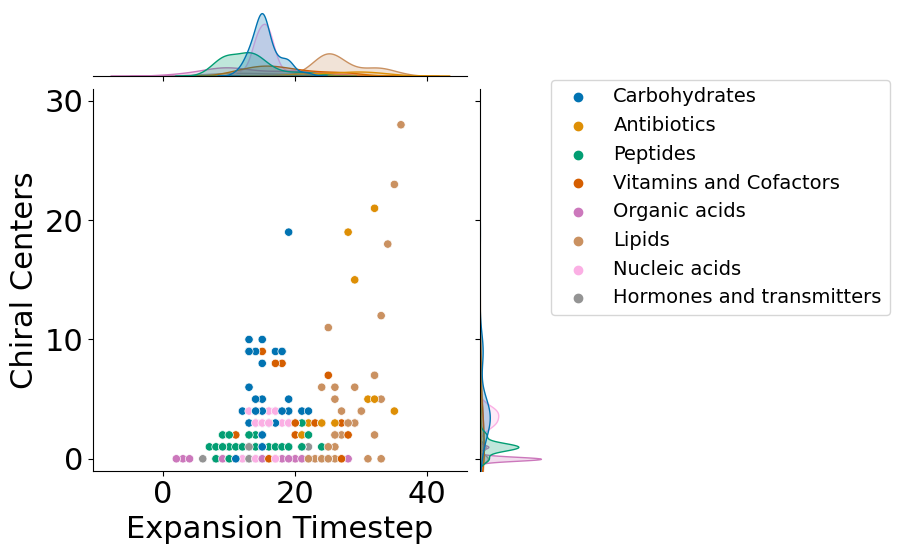

In [121]:
g = sns.jointplot(data=df[df["Labels"] != ""], x="Expansion Timestep", y="Chiral Centers", 
                  hue="Labels", palette="colorblind", ylim=(-1,31))

#plt.legend(bbox_to_anchor=(1,1), prop={"size":14})
g.ax_joint.legend(bbox_to_anchor=(1.2,1.05), prop={"size":14})

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

# Universality


In [122]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import csv
from collections import Counter
import matplotlib.gridspec as gridspec


In [123]:
font = {"family" : "normal",
    "size" : 22}

for key, value in font.items():
    plt.rcParams.update({"font." + key : value})

mg_color = "#009E73"
e_color = "#E69F03"
b_color = "#0B77B5"
a_color = "#D65E00"
pt_color = "#EA9999"

chiral_ls = "solid"
achiral_ls = "dashed"

In [124]:
def make_AUC(u, label, c, ax):
  yvals = list(u.values())
  xvals = np.linspace(0, 1, num=len(yvals))
  #Calculate AUC using composite travezoidal rule
  area = np.trapz(yvals, dx=xvals[1])

  if c == "":
    ax.plot(xvals, yvals, label = label + " AUC=" + str(round(area,2)))
  else:
    ax.plot(xvals, yvals, label = label + " AUC=" + str(round(area,2)), color=c)

  ax.legend()

def make_AUC_dashes(u, label, c, ls, ax):
  yvals = list(u.values())
  xvals = np.linspace(0, 1, num=len(yvals))

  #Calculate AUC using composite travezoidal rule
  area = np.trapz(yvals, dx=xvals[1])

  ax.plot(xvals, yvals, label = label + " AUC=" + str(round(area,2)), color=c, 
    linestyle=ls, linewidth=4)

  ax.legend(prop={"size":13.5})

  return yvals

#Separate domains into chiral vs achiral
#df is the chiral dataframe (columns=['Index', 'C', 'Smiles', 'Chiral_Centers'])
def find_chiral(u, df):
  achiral = {}
  chiral = {}

  for index, row in df.iterrows():
    if row["C"] in u:
      if row["Chiral_Centers"] > 0:
        chiral[row["C"]] = u[row["C"]]
      else:
        achiral[row["C"]] = u[row["C"]]

  return chiral, achiral


def get_chiral_difference(chiral_values, achiral_values, c, l, ax):

    #Step 1: get rank-order percentile values
    m_chiral_percentiles = []
    for i in np.linspace(0, len(chiral_values)-1, 100):
        m_chiral_percentiles.append(chiral_values[int(i)])

    m_achiral_percentiles = []
    for i in np.linspace(0, len(achiral_values)-1, 100):
        m_achiral_percentiles.append(achiral_values[int(i)])

    #Step 2: find difference
    m_diffs = list(np.array(m_chiral_percentiles) - np.array(m_achiral_percentiles))

    #Step 3: plot
    label = ax.plot(m_diffs, color=c, linewidth=3, label=l)

    return label

In [125]:
#Read in chirality of all KEGG compounds
fp = "../Data/chiral_molweight_formula_labels.csv"
df = pd.read_csv(fp)
df.head()

#Read in occurence data & create universality percentages

num_bacteria = 10434
num_archaea = 1194
num_eukarya = 267
num_metagenomes=  6112

with open("../Data/archaea_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  a_cpd_occurances = dict(reader)

with open("../Data/bacteria_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  b_cpd_occurances = dict(reader)

with open("../Data/eukarya_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  e_cpd_occurances = dict(reader)

with open("../Data/metagenome_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  m_cpd_occurances = dict(reader)

#Translate occurances into % universality
a_cpd_universality = {}
b_cpd_universality = {}
e_cpd_universality = {}
m_cpd_universality = {}

#Num archaea: 1194
for item in a_cpd_occurances.items():
  a_cpd_universality[item[0]] = float(item[1]) / num_archaea

#num bacteria = 10434
for item in b_cpd_occurances.items():
  b_cpd_universality[item[0]] = float(item[1]) / num_bacteria

#Num eukarya: 267
for item in e_cpd_occurances.items():
  e_cpd_universality[item[0]] = float(item[1]) / num_eukarya

#Num metagenomes = 6112
for item in m_cpd_occurances.items():
  m_cpd_universality[item[0]] = float(item[1]) / num_metagenomes

#Create universality dictionaries across bacteria, archaea, and eukarya (and various combinations) - easier for plotting & calculations

#Convert keys to integers, combine dictionaries
a_cpd_occurances = dict([a, int(x)] for a, x in a_cpd_occurances.items())
b_cpd_occurances = dict([a, int(x)] for a, x in b_cpd_occurances.items())
e_cpd_occurances = dict([a, int(x)] for a, x in e_cpd_occurances.items())
ba_occurances = Counter(a_cpd_occurances) + Counter(b_cpd_occurances)
pt_occurances = Counter(a_cpd_occurances) + Counter(b_cpd_occurances) + Counter(e_cpd_occurances)

#Find universality of bacteria & archaea combined
ba_cpd_universality = {}
num_ba = num_archaea + num_bacteria
for item in ba_occurances.items():
  ba_cpd_universality[item[0]] = float(item[1]) / num_ba


#Universality of pan-taxa (bacteria, archaea, eukarya combined)
pt_cpd_universality = {}
num_pt = num_archaea + num_bacteria + num_eukarya
for item in pt_occurances.items():
  pt_cpd_universality[item[0]] = float(item[1]) / num_pt

#Find unversalities, and rank-order each
a_chiral_universality, a_achiral_universality = find_chiral(a_cpd_universality, df)
a_chiral_universality = {k: v for k, v in sorted(a_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
a_achiral_universality = {k: v for k, v in sorted(a_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

b_chiral_universality, b_achiral_universality = find_chiral(b_cpd_universality, df)
b_chiral_universality = {k: v for k, v in sorted(b_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
b_achiral_universality = {k: v for k, v in sorted(b_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

e_chiral_universality, e_achiral_universality = find_chiral(e_cpd_universality, df)
e_chiral_universality = {k: v for k, v in sorted(e_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
e_achiral_universality = {k: v for k, v in sorted(e_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

m_chiral_universality, m_achiral_universality = find_chiral(m_cpd_universality, df)
m_chiral_universality = {k: v for k, v in sorted(m_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
m_achiral_universality = {k: v for k, v in sorted(m_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

ba_chiral_universality, ba_achiral_universality = find_chiral(ba_cpd_universality, df)
ba_chiral_universality = {k: v for k, v in sorted(ba_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
ba_achiral_universality = {k: v for k, v in sorted(ba_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

pt_chiral_universality, pt_achiral_universality = find_chiral(pt_cpd_universality, df)
pt_chiral_universality = {k: v for k, v in sorted(pt_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
pt_achiral_universality = {k: v for k, v in sorted(pt_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


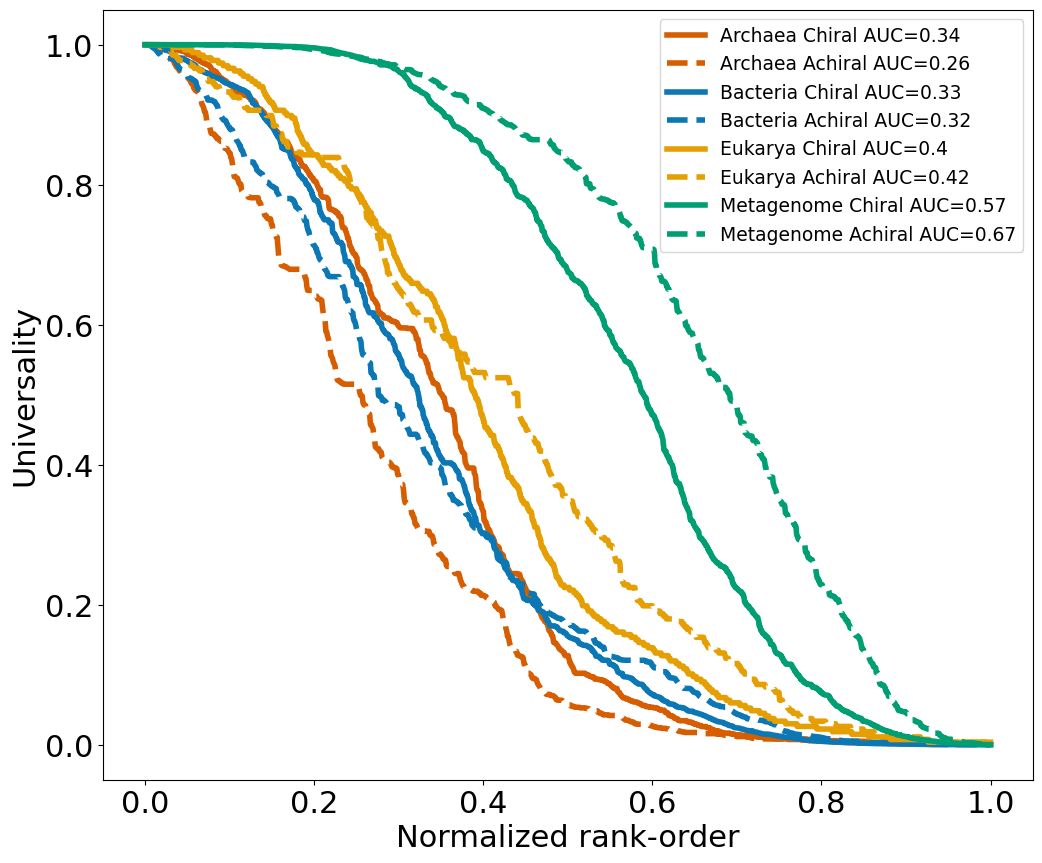

In [126]:
#All three domains together
fig, ax = plt.subplots(figsize=(12,10))
a_chiral = make_AUC_dashes(a_chiral_universality, "Archaea Chiral", a_color, chiral_ls, ax)
a_achiral = make_AUC_dashes(a_achiral_universality, "Archaea Achiral", a_color, achiral_ls, ax)

b_chiral = make_AUC_dashes(b_chiral_universality, "Bacteria Chiral", b_color, chiral_ls, ax)
b_achiral = make_AUC_dashes(b_achiral_universality, "Bacteria Achiral", b_color, achiral_ls, ax)

e_chiral = make_AUC_dashes(e_chiral_universality, "Eukarya Chiral", e_color, chiral_ls, ax)
e_achiral = make_AUC_dashes(e_achiral_universality, "Eukarya Achiral", e_color, achiral_ls, ax)

m_chiral = make_AUC_dashes(m_chiral_universality, "Metagenome Chiral", mg_color, chiral_ls, ax)
m_achiral = make_AUC_dashes(m_achiral_universality, "Metagenome Achiral", mg_color, achiral_ls, ax)
# make_AUC(ba_chiral_universality, "BA Chiral")
# make_AUC(ba_achiral_universality, "BA Achiral")
# make_AUC(ba_chiral_universality, "PT Chiral")
# make_AUC(ba_achiral_universality, "PT Achiral")

#plt.title("AUC All Compounds - Chiral Split")
ax.set_ylabel("Universality")
ax.set_xlabel("Normalized rank-order")

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1


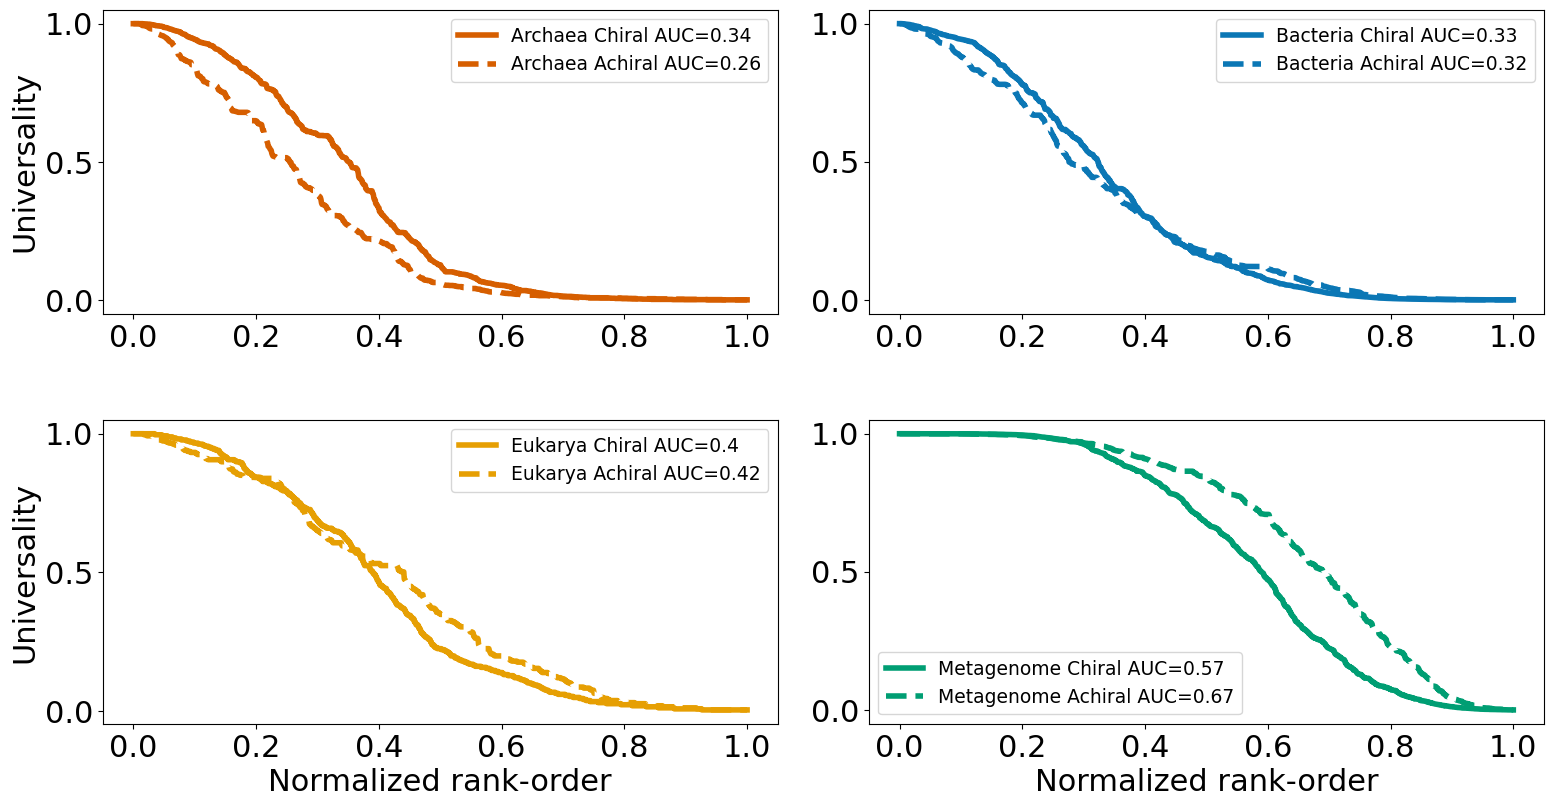

In [127]:
plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(4,2)

ax1 = plt.subplot(gs[0,0])
make_AUC_dashes(a_chiral_universality, "Archaea Chiral", a_color, chiral_ls, ax1)
make_AUC_dashes(a_achiral_universality, "Archaea Achiral", a_color, achiral_ls, ax1)

ax2 = plt.subplot(gs[0,1])
make_AUC_dashes(b_chiral_universality, "Bacteria Chiral", b_color, chiral_ls, ax2)
make_AUC_dashes(b_achiral_universality, "Bacteria Achiral", b_color, achiral_ls, ax2)

ax3 = plt.subplot(gs[1,0])
make_AUC_dashes(e_chiral_universality, "Eukarya Chiral", e_color, chiral_ls, ax3)
make_AUC_dashes(e_achiral_universality, "Eukarya Achiral", e_color, achiral_ls, ax3)

ax4 = plt.subplot(gs[1,1])
make_AUC_dashes(m_chiral_universality, "Metagenome Chiral", mg_color, chiral_ls, ax4)
make_AUC_dashes(m_achiral_universality, "Metagenome Achiral", mg_color, achiral_ls, ax4)

ax1.set_ylabel("Universality")
ax3.set_ylabel("Universality")
ax3.set_xlabel("Normalized rank-order")
ax4.set_xlabel("Normalized rank-order")

plt.tight_layout()

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1


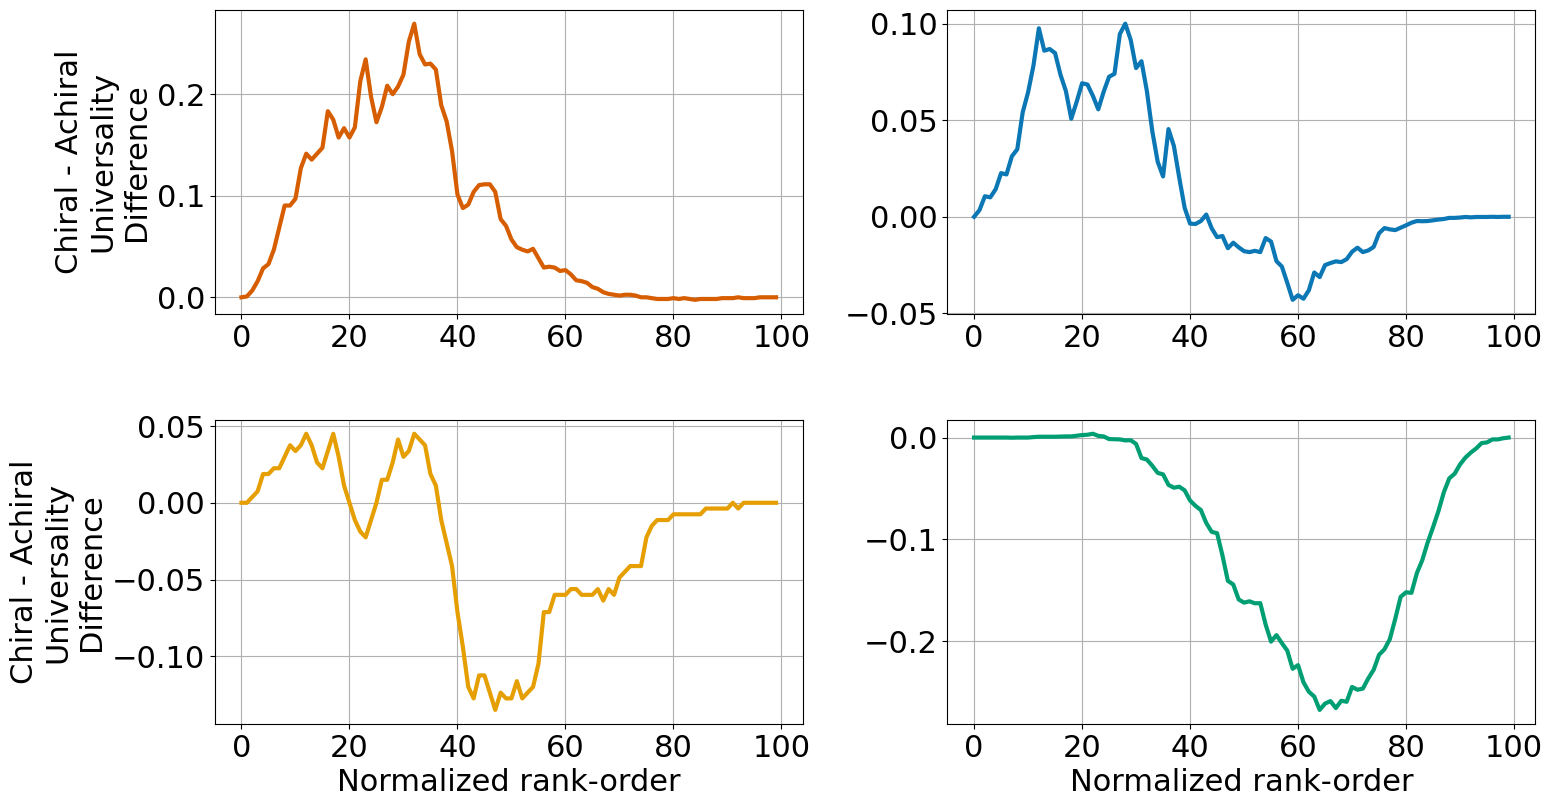

In [128]:
plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(4,2)

ax1 = plt.subplot(gs[0,0])
get_chiral_difference(a_chiral, a_achiral, a_color, "Archaea", ax1)

ax2 = plt.subplot(gs[0,1])
get_chiral_difference(b_chiral, b_achiral, b_color, "Bacteria", ax2)

ax3 = plt.subplot(gs[1,0])
get_chiral_difference(e_chiral, e_achiral, e_color, "Eukarya", ax3)

ax4 = plt.subplot(gs[1,1])
get_chiral_difference(m_chiral, m_achiral, mg_color, "Metagenome", ax4)


ax1.set_ylabel("Chiral - Achiral\nUniversality\nDifference")
ax3.set_ylabel("Chiral - Achiral\nUniversality\nDifference")
ax3.set_xlabel("Normalized rank-order")
ax4.set_xlabel("Normalized rank-order")

ax1.grid()
ax2.grid()
ax3.grid()
ax4.grid()

plt.tight_layout()

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1


#### AUC scores for chiral modulating / conserving / achiral conserving domain-specific reactions

In [129]:
import csv

def get_AUC(yvals):
  xvals = np.linspace(0, 1, num=len(yvals))

  #Calculate AUC using composite travezoidal rule
  area = np.trapz(yvals, dx=xvals[1])
  # #AUC using Simpson's rule
  # area = simps(yvals, dx=xvals[1])
  # print(label, "Simpson's area:", area)
  
  return round(area, 3)

def plot_classes(universality, ax, c, title):
  modulating_universality = [u for r, u in universality.items() if r in modulating_rxns]
  chiral_conserve_universality = [u for r, u in universality.items() if r in chiral_conserving_rxns]
  achiral_conserve_universality = [u for r, u in universality.items() if r in achiral_conserving_rxns]

  ax.plot(modulating_universality, linestyle="solid", linewidth=3, color=c, label=f"Chiral Modulating\nAUC={get_AUC(modulating_universality)}")
  ax.plot(chiral_conserve_universality, linestyle="dashed", linewidth=3, color=c, label=f"Chiral Conserving\nAUC={get_AUC(chiral_conserve_universality)}")
  ax.plot(achiral_conserve_universality, linestyle="dotted", linewidth=3, color=c, label=f"Achiral Conserving\nAUC={get_AUC(achiral_conserve_universality)}")

  ax.legend(prop={"size": 8})
  ax.set_title(title, color=c)

### Modulating - from Kamesh
modulate_df = pd.read_csv("../Data/kegg_reactions_with_mol_weights_comprehensive_v8.csv")

modulating = []
achiral_conserve = []
chiral_conserve = []

modulating_rxns = []
achiral_conserving_rxns = []
chiral_conserving_rxns = []

for i in range(0, max(modulate_df["Network_step"])):
    sub_df = modulate_df[modulate_df["Network_step"] == i]

    chiral_modulating_df = sub_df[sub_df["Chiral_modulating"] == 1]
    modulating.append(len(chiral_modulating_df))
    if not chiral_modulating_df.empty:
        modulating_rxns.extend(list(chiral_modulating_df["_key"]))
    
    achiral_conserving_df = sub_df[sub_df["Achiral_conserving"] == 1]
    achiral_conserve.append(len(achiral_conserving_df))
    if not achiral_conserving_df.empty:
        achiral_conserving_rxns.extend(list(achiral_conserving_df["_key"]))

    chiral_conserving_df = sub_df[sub_df["Chiral_conserving"] == 1]
    chiral_conserve.append(len(chiral_conserving_df))
    if not chiral_conserving_df.empty:
        chiral_conserving_rxns.extend(list(chiral_conserving_df["_key"]))

print(modulating_rxns)
print(chiral_conserving_rxns)
print(achiral_conserving_rxns)

### Read in occurence data & create universality percentages
num_bacteria = 11759
num_archaea = 1282
num_eukarya = 243
num_metagenomes = 18725

with open("../Data/Archaea_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  a_rxn_occurances = dict(reader)

with open("../Data/Bacteria_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  b_rxn_occurances = dict(reader)

with open("../Data/Eukaryota_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  e_rxn_occurances = dict(reader)

with open("../Data/Metagenome_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  m_rxn_occurances = dict(reader)

#Translate occurances into % universality
a_rxn_universality = {}
b_rxn_universality = {}
e_rxn_universality = {}
m_rxn_universality = {}

#Num archaea: 1194
for item in a_rxn_occurances.items():
  a_rxn_universality[item[0]] = float(item[1]) / num_archaea

#num bacteria = 10434
for item in b_rxn_occurances.items():
  b_rxn_universality[item[0]] = float(item[1]) / num_bacteria

#Num eukarya: 267
for item in e_rxn_occurances.items():
  e_rxn_universality[item[0]] = float(item[1]) / num_eukarya

#Num metagenomes = 6112
for item in m_rxn_occurances.items():
  m_rxn_universality[item[0]] = float(item[1]) / num_metagenomes

['R08122', 'R00469', 'R00776', 'R01627', 'R02422', 'R03084', 'R06989', 'R00478', 'R00588', 'R02423', 'R02425', 'R02713', 'R05079', 'R06990', 'R08474', 'R09717', 'R09718', 'R10908', 'R00220', 'R00347', 'R00590', 'R01826', 'R03995', 'R05077', 'R06064', 'R06604', 'R08475', 'R09683', 'R00213', 'R00221', 'R00226', 'R00250', 'R00279', 'R00339', 'R00340', 'R00357', 'R00359', 'R00360', 'R00369', 'R00372', 'R00373', 'R00471', 'R00532', 'R00658', 'R00673', 'R00679', 'R00751', 'R00753', 'R00782', 'R00985', 'R01031', 'R01782', 'R01784', 'R01874', 'R02754', 'R03277', 'R03896', 'R04152', 'R04252', 'R05553', 'R05758', 'R05861', 'R06063', 'R06171', 'R06605', 'R07476', 'R08195', 'R08196', 'R10283', 'R11333', 'R00261', 'R00262', 'R00319', 'R00325', 'R00409', 'R00481', 'R00489', 'R00490', 'R00677', 'R00681', 'R00685', 'R00761', 'R00896', 'R00907', 'R00908', 'R00986', 'R00996', 'R01082', 'R01302', 'R01466', 'R01648', 'R01682', 'R01714', 'R01715', 'R01751', 'R02278', 'R02279', 'R02429', 'R02522', 'R02752',

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


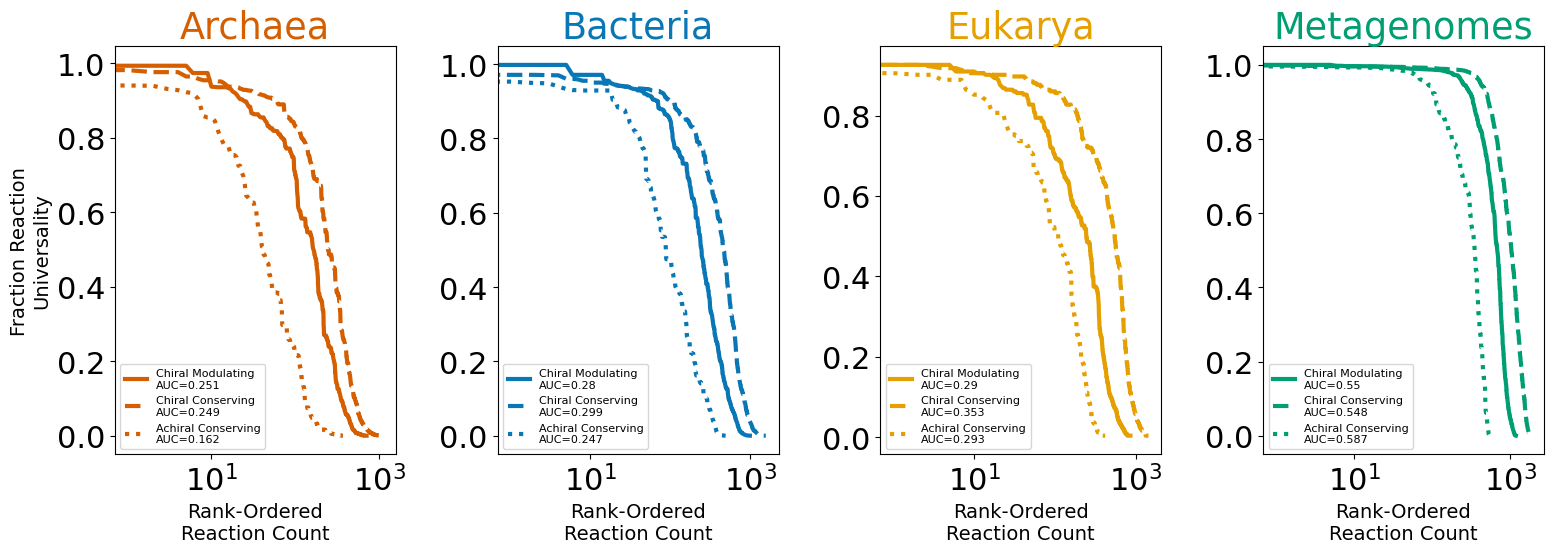

In [130]:
### Goal - 4 plots (1 per domain) with AUC scores in legend
from matplotlib.gridspec import GridSpec

colors = {"archaea": "#D55E00", 
         "bacteria": "#0977B5",
         "eukarya": "#E69F00",
         "metagenome": "#009E73",
         "pantaxa": "#EA9999",
          "chiral": "#34CCFF",
          "achiral": "#FFC012",
          "mixed": "#abdbfc",
          "luca": "grey"}

fig = plt.figure(figsize=(16,6))
gs = GridSpec(1,4)

ax_archaea = fig.add_subplot(gs[:, 0])
ax_bacteria = fig.add_subplot(gs[:,1])
ax_eukarya= fig.add_subplot(gs[:, 2])
ax_mg = fig.add_subplot(gs[:, 3])

plot_classes(a_rxn_universality, ax_archaea, colors["archaea"], "Archaea")
plot_classes(b_rxn_universality, ax_bacteria, colors["bacteria"], "Bacteria")
plot_classes(e_rxn_universality, ax_eukarya, colors["eukarya"], "Eukarya")
plot_classes(m_rxn_universality, ax_mg, colors["metagenome"], "Metagenomes")

ax_archaea.set_xscale("log")
ax_bacteria.set_xscale("log")
ax_eukarya.set_xscale("log")
ax_mg.set_xscale("log")

ax_archaea.set_ylabel("Fraction Reaction\nUniversality", fontsize=14)
ax_archaea.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_bacteria.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_eukarya.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_mg.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)

plt.tight_layout()

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

### Chiral Centers / Degrees

In [131]:
fp = "../Data/br08001.json"
with open(fp) as json_file:
  br_json = json.load(json_file)

classes = []
cpd_class = {}
for key1 in br_json["children"]:
  classes.append(key1["name"])
  for key2 in key1["children"]:
    for key3 in key2["children"]:
      for cpd in key3["children"]:
        cpd_class[cpd["name"][:6]] = key1["name"]


fp = "../Data/cpd_appearence_data.csv"
df = pd.read_csv(fp)

#Find compounds with classifications under BRITE that appear in the expansion
overlap = {}

for cpd in df["Compound"]:
  if cpd in cpd_class.keys():
    overlap[cpd] = cpd_class[cpd]
  else:
    overlap[cpd] = ""

df["Labels"] = df["Compound"].map(overlap)

for c in classes:
  #Make sub-dataframe for each class
  sub_df = df[df["Labels"] == c]
  chiral_cpds = 0
  for item, row in sub_df.iterrows():
    if row["Chiral_Centers"] > 0:
      chiral_cpds += 1
  if len(sub_df) != 0:
    print("Chirality of", c, "is:", float(chiral_cpds)/len(sub_df))

heavy_atoms = []
heavy_atoms_2 = []
#Find number of heavy (non-H) atoms for each cpd
for f in df["Formula"]:
  try: #Account for nans
    formula = chemparse.parse_formula(f)
    sum = 0
    for atom, count in formula.items():
      if atom != "H":
        sum += count
    #Bins of 20 (10 bins) & 40 (5 bins) heavy atoms
    if int(sum/40) == 0:
      heavy_atoms.append("0 - 20th")
    elif int(sum/40) == 1:
      heavy_atoms.append("21 - 40th")
    elif int(sum/40) == 2:
      heavy_atoms.append("41 - 60th")
    elif int(sum/40) == 3:
      heavy_atoms.append("61 - 80th")
    else:
      heavy_atoms.append("81 - 100th")

  except:
    heavy_atoms.append("0 - 20th")

df["Heavy Atoms"] = heavy_atoms

df = df.rename(columns={"Timestep_Appear": "Expansion Step", "Chiral_Centers": "Chiral Centers"})

df.sort_values(by="Heavy Atoms")

degree_df = pd.read_csv("../Data/undirected_cp_cp_degrees_from_reaction_edges.csv")

df = pd.merge(df, degree_df, left_on=["Compound"], right_on=["Cpd"])


Chirality of Organic acids is: 0.125
Chirality of Lipids is: 0.5227272727272727
Chirality of Carbohydrates is: 0.9682539682539683
Chirality of Nucleic acids is: 0.8936170212765957
Chirality of Peptides is: 0.8431372549019608
Chirality of Vitamins and Cofactors is: 0.6451612903225806
Chirality of Hormones and transmitters is: 0.4166666666666667
Chirality of Antibiotics is: 1.0


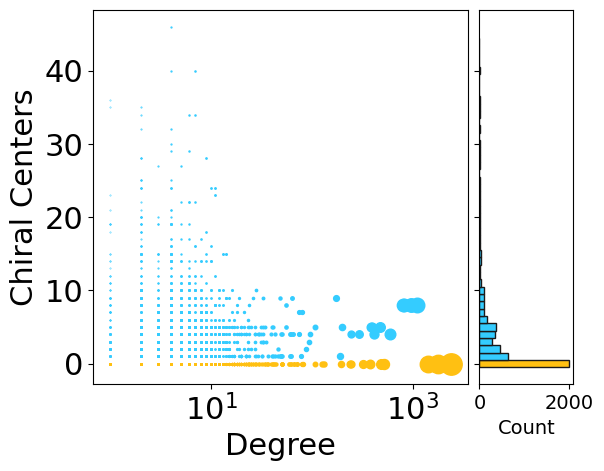

In [132]:
def scatter_hist(x, y, ax, ax_histy, c):
    achiral_color = "#FFC012"
    chiral_color = "#34CCFF"

    ax_histy.tick_params(axis="y", labelleft=False)

    #Plot by chiral/achiral color, and size by degree
    for i in range(len(x)):
        if y[i] == 0:
            ax.scatter(x[i], y[i], color=achiral_color, s=x[i]/10)
        else:
            ax.scatter(x[i], y[i], color=chiral_color, s=x[i]/10)

    #Set bins to middle of chiral center y-values to line up across axes
    bins = np.arange(-0.5,max(y)-0.5,1)
    cnts, values, bars = ax_histy.hist(np.array(y)-0.5, orientation='horizontal', color=c, bins=bins, edgecolor="k")

    #Make sure labels are smaller on histogram than scatter plot
    ax_histy.set_xlabel("Count", fontsize=14)
    ax_histy.tick_params(axis='both', which='major', labelsize=14)

    #Change color of histogram bars
    for i, (cnt, value, bar) in enumerate(zip(cnts, values, bars)):
        if i == 0:
            bar.set_facecolor(achiral_color)
        else:
            bar.set_facecolor(chiral_color)


fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2,  width_ratios=(4, 1), height_ratios=(1, 4),
                      left=0.1, right=0.9, bottom=0.1, top=0.9,
                      wspace=0.05, hspace=0.05)
ax = fig.add_subplot(gs[1, 0])
#ax_histx = fig.add_subplot(gs[0, 0], sharex=ax) #No top histogram
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)
scatter_hist(list(df["Degree"]), list(df["Chiral Centers"]), ax, ax_histy, "k")

#ax.set_yticklabels(["", "0", "5", "10"])

ax.set_xscale("log")

ax.set_xlabel("Degree")
ax.set_ylabel("Chiral Centers")

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

# Reaxys Sampling


In [133]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pickle
import numpy as np

In [134]:
#Matplotlib defaults
chnops_color = "#477C7D"
kegg_color = "#AA0E35"

plt.rcParams.update({'font.size': 22})

In [135]:
chnops = pickle.load(file=open("../Data/chiral_chnops_sampling_FULL.p", "rb"))
kegg = pickle.load(file=open("../Data/chiral_kegg_sampling_FULL.p", "rb"))

In [136]:
mws = np.arange(100,7100,100) #Molecular Weights (x-axis)

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


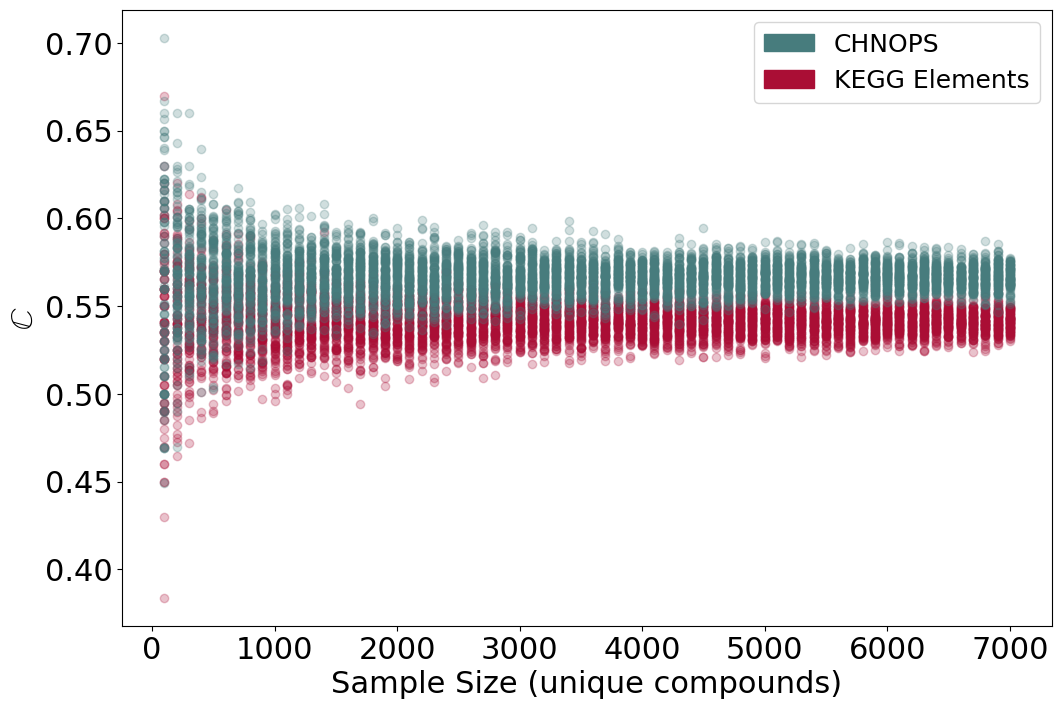

In [137]:
plt.figure(figsize=(12,8))

#Scatter plot first
for i in range(len(chnops)):
    plt.scatter([mws[i]] * len(kegg[i]), kegg[i], color=kegg_color, alpha=0.25)
    plt.scatter([mws[i]] * len(chnops[i]), chnops[i], color=chnops_color, alpha=0.25)

plt.ylabel("$\mathbb{C}$")
plt.xlabel("Sample Size (unique compounds)")

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

plt.legend(handles=[chnops_patch, kegg_patch], prop={"size": 18})

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1


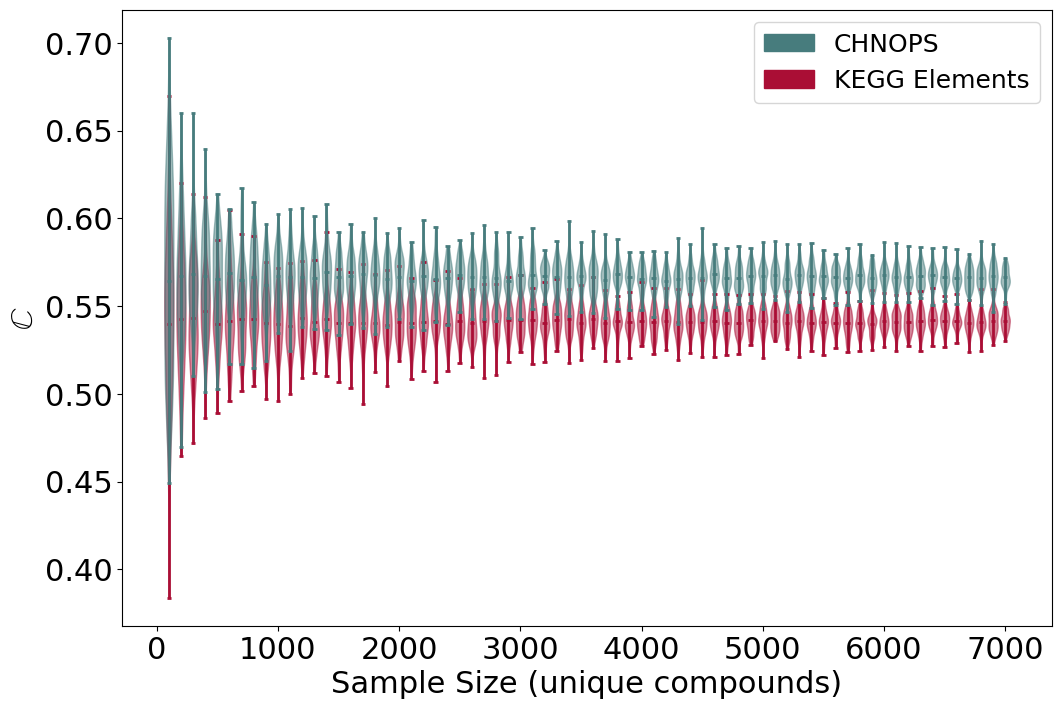

In [138]:
fig, ax = plt.subplots(1,1,figsize=(12,8))

#Violin plots second
kegg_violins = ax.violinplot(kegg, positions=mws, widths=75, showmeans=True)
chnops_violins = ax.violinplot(chnops, positions=mws, widths=75, showmeans=True)

# Color all CHNOPS violins
for partname in ('cbars','cmins','cmaxes','cmeans'):
    vp = chnops_violins[partname]
    vp.set_edgecolor(chnops_color)
    vp.set_linewidth(2)

for pc in chnops_violins['bodies']:
    pc.set_facecolor(chnops_color)
    pc.set_edgecolor(chnops_color)
    pc.set_alpha(0.5)

#Now do all KEGG violins
for partname in ('cbars','cmins','cmaxes','cmeans'):
    vp = kegg_violins[partname]
    vp.set_edgecolor(kegg_color)
    vp.set_linewidth(2)

for pc in kegg_violins['bodies']:
    pc.set_facecolor(kegg_color)
    pc.set_edgecolor(kegg_color)
    pc.set_alpha(0.5)

ax.set_ylabel("$\mathbb{C}$")
ax.set_xlabel("Sample Size (unique compounds)")

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

plt.legend(handles=[chnops_patch, kegg_patch], prop={"size": 18})

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1

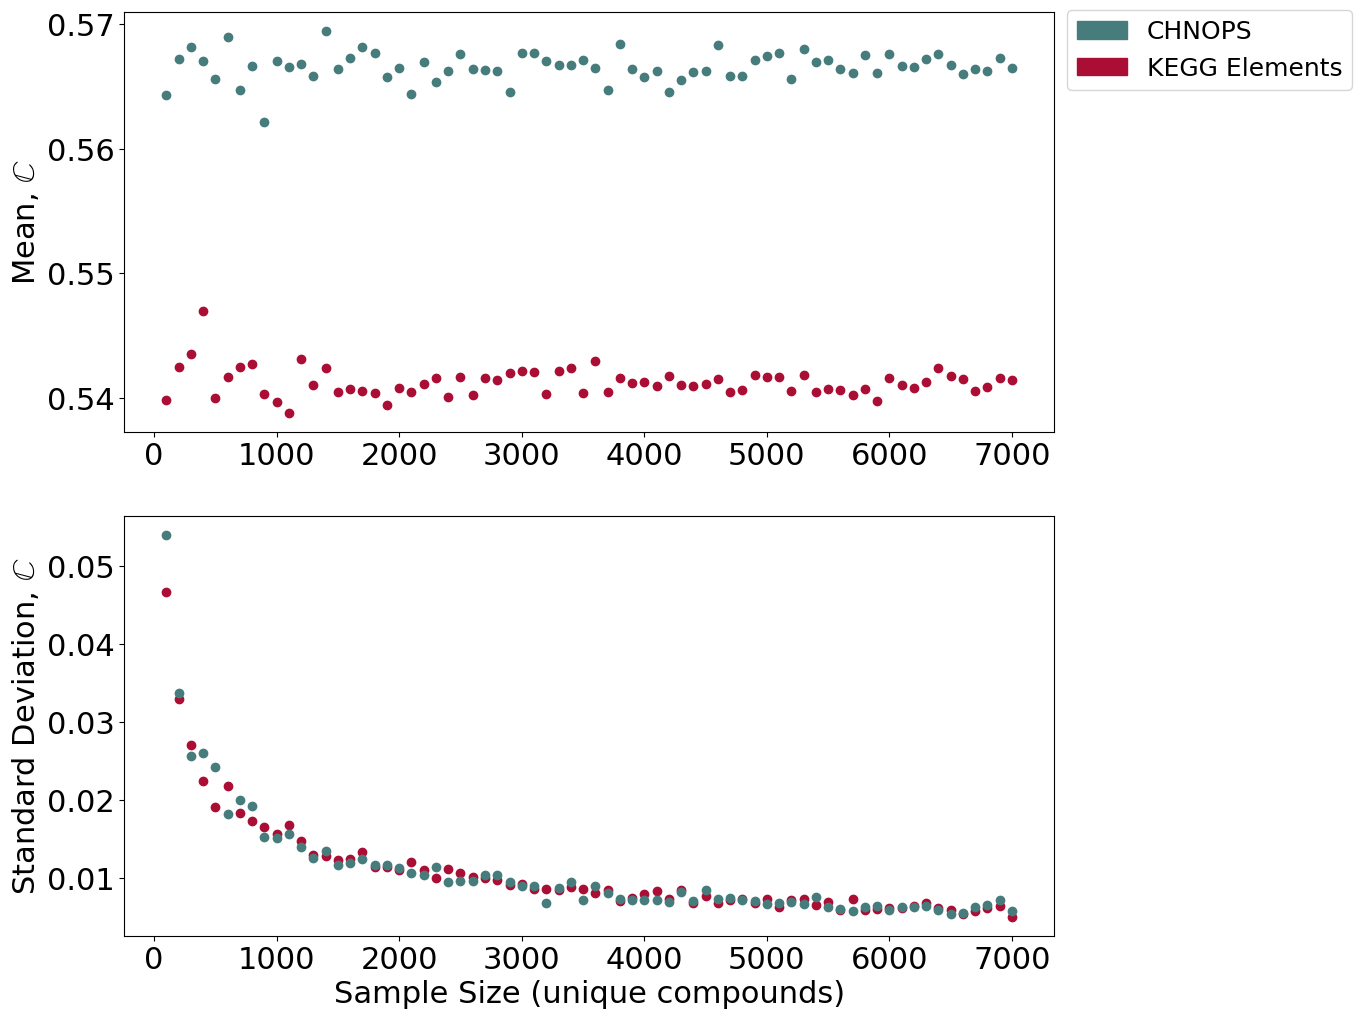

In [139]:
## Mean & StdDev of all samples
plt.figure(figsize=(12,12))
gs = gridspec.GridSpec(2,1)

#Means
ax1 = plt.subplot(gs[0,0])
ax1.scatter(mws, [np.mean(s) for s in kegg], color=kegg_color)
ax1.scatter(mws, [np.mean(s) for s in chnops], color=chnops_color)
ax1.set_ylabel("Mean, $\mathbb{C}$")

#Stdevs
ax2 = plt.subplot(gs[1,0])
ax2.scatter(mws, [np.std(s) for s in kegg], color=kegg_color)
ax2.scatter(mws, [np.std(s) for s in chnops], color=chnops_color)
ax2.set_ylabel("Standard Deviation, $\mathbb{C}$")
ax2.set_xlabel("Sample Size (unique compounds)")

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

ax1.legend(handles=[chnops_patch, kegg_patch], prop={"size": 18}, bbox_to_anchor=(1,1.035))

plt.savefig(f"SIFig_{fig_count}.svg", format="svg")
fig_count+=1